# Backtesting — Lévy / NIG sobre panel líder BYMA

Notebook que corre, paso a paso, el pipeline cerrado de `cierre_especificacion_estrategia.qmd`
(Sección 5): carga de datos, ventana $W_i$ por activo, calibración NIG walk-forward,
logit pooled con efectos fijos, cartera equal-weight de 5 activos y comparación contra
un conjunto de comparadores pasivos y activos.

**Requisito**: los 13 archivos `.py` del framework (`nig_model.py`, `window_selection.py`,
`levy_estimators.py`, `signal_generator.py`, `backtest_engine.py`, `comparators.py`,
`protection.py`, `liquidity.py`, `sensitivity.py`, `data_loader.py`, `performance_metrics.py`,
`macro_data.py`, `main.py`) tienen que estar en la **misma carpeta** que este notebook —
las celdas de código los importan tal cual, no duplican su lógica. Instalar antes:

```
pip install -r requirements.txt
```

**Estado de esta versión (Entrega #4, Fases 0-6).**

- *Fase 0:* catálogo de 18 fechas, costo **por lado**, contabilidad con retornos simples,
  precios `Adj Close` explícitos.
- *Fase 1 — entrenamiento point-in-time:* el logit ya **no** se ajusta sobre toda la
  muestra. Para decidir la exposición del día $t$ se usan solo eventos cuyo horizonte de
  5 días terminó antes de $t$ (`known_at < t`). La exposición es out-of-sample.
- *Fase 2 — ventanas más cortas y justificadas:* el criterio de estabilización de $W_E$ es
  configurable. Se demostró que el criterio original no estabiliza **ni siquiera en una
  serie NIG estacionaria**, así que el techo de ~2.700 días era un artefacto del criterio.
  La elección se hace con la tabla de diagnóstico de la sección 2a, **no** con Sharpe.
- *Fase 3 — comparador:* la cartera se simula con tenencias explícitas (las posiciones
  derivan con los precios, cada rebalanceo paga costos y la compra inicial se cobra a
  todos). La frecuencia de rebalanceo entre activos es un supuesto explícito (mensual por
  defecto). Comparadores: equal-weight 100%, exposición fija, vol targeting, MA200 y Merval.
- *Fase 4 — ¿protege?:* segmentación dentro/fuera de episodios y por régimen de volatilidad,
  tabla por episodio, leave-one-episode-out, VaR/ES rolling con Kupiec y Christoffersen,
  bootstrap por bloques de las diferencias, y Deflated Sharpe y PBO sobre las
  configuraciones probadas.
- *Fase 5 — liquidez y salida:* costo variable diario (Corwin-Schultz), chequeo del tope de
  10% del ADV con capacidad de la estrategia, y piso de exposición por drawdown (evaluado,
  no activado por defecto).
- *Fase 6 — sensibilidad:* variación de un parámetro por vez (u, h, criterio de W, banda de
  histéresis, costo, rebalanceo), gráfico tornado, grilla factorial de los dos parámetros más
  sensibles, grilla del piso por drawdown y resultados por activo.

- *Variables macro (Entrega #2):* tasa libre de riesgo en pesos (pase a 1 día del BCRA, como proxy de la caución) para Sharpe/Sortino en exceso y como rendimiento de la caja; tipo de cambio oficial y T-bill 3m para la vista en dólares. No son insumo de las reglas de señal.

Detalle en `NOTAS_IMPLEMENTACION.md`.

## Setup: imports y parámetros

**Cómo correr este notebook.**

Esta entrega se ejecutó con COMPARAR_CRITERIOS = True y RECALIBRATION_STEP = 1; los resultados reportables son los de CONFIG (sección 2b).

| Corrida | `COMPARAR_CRITERIOS` | `RECALIBRATION_STEP` | Para qué |
|---|---|---|---|
| 1 | `True` | `1` | Tabla de criterios de $W$ + variantes de evento. Elegir la configuración. (así se ejecutó esta entrega) |
| final | `False` | `1` | Resultado reportable con la configuración elegida (`CONFIG`, sección 2b). |

Este paquete se corrió con paso 1 (recalibración diaria). Con `cache_nig/` presente la
corrida tarda minutos; sin caché, del orden de 10 horas. Un paso mayor (p. ej. 5) es más
rápido pero da resultados preliminares y **no** reutiliza el caché, que lleva el paso en el nombre.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from data_loader import load_benchmark, load_price_data
from comparators import REBALANCE_RULES, rebalance_sensitivity
import protection as pr
import liquidity as lq
import sensitivity as se
from window_selection import EPISODE_CATALOG, WINDOW_CRITERIA, WINDOW_COMBINE
from signal_generator import EVENT_DEFINITIONS, TAU_METHODS
from backtest_engine import cost_table
from main import PipelineConfig, run_pipeline, compare_window_criteria, save_results

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (11, 4)

TICKERS = ["GGAL.BA", "PAMP.BA", "YPFD.BA", "BMA.BA", "BYMA.BA"]

COMPARAR_CRITERIOS = True   # True: incluye la tabla de criterios de W (así se ejecutó esta entrega) | False: solo CONFIG
RECALIBRATION_STEP = 1      # El caché cache_nig/ está calculado con paso 1; no cambiar
CORRER_GRILLA = True        # Fase 4: grilla de configuraciones para Deflated Sharpe y PBO (una vez; queda en CSV)
CORRER_SENSIBILIDAD = True  # Fase 6: OFAT + factorial (una vez; queda en CSV)

## Paso 1 — Carga de datos (Sección 1)

Descarga los 5 activos del panel líder de BYMA vía *yfinance*, con el corte por activo de la Sección 1 (2015-01-01 para GGAL/PAMP/YPFD/BMA; sin corte para BYMA, que cotiza recién desde 2017). La primera vez se guarda un snapshot en *datos/precios.pkl*; las corridas siguientes lo leen, de modo que el resultado no depende de la red ni de la fecha y la caché *cache_nig/* sigue siendo válida.

In [4]:
import os

# Snapshot de precios: la caché del NIG se identifica por una huella de los datos (incluye la última
# fecha). Si se vuelve a descargar de yfinance otro día, la huella cambia y se recalcula TODO.
# Por eso los precios se guardan una vez y las corridas siguientes los leen de acá.
PRECIOS_PKL = "datos/precios.pkl"
if os.path.exists(PRECIOS_PKL):
    snap = pd.read_pickle(PRECIOS_PKL)
    price_data, merval_full = snap["price_data"], snap.get("merval")
    print(f"Precios leídos de {PRECIOS_PKL} (borrar el archivo para volver a descargar; esto invalida cache_nig/).")
else:
    price_data = load_price_data(tickers=TICKERS)  # usa el corte por activo por defecto
    # S&P Merval: solo como referencia (índice, no invertible tal cual).
    try:
        merval_full = load_benchmark("^MERV")
    except Exception as exc:
        print(f"No se pudo cargar el Merval ({exc}); se sigue sin él.")
        merval_full = None
    try:
        os.makedirs("datos", exist_ok=True)
        pd.to_pickle({"price_data": price_data, "merval": merval_full}, PRECIOS_PKL)
    except OSError as exc:
        print(f"No se pudo guardar el snapshot de precios ({exc}); la corrida sigue.")
returns_by_asset = {t: price_data[t]["log_return"] for t in price_data}
merval = merval_full["log_return"] if merval_full is not None else None

pd.DataFrame({
    "Ticker": list(returns_by_asset.keys()),
    "Observaciones diarias": [len(r) for r in returns_by_asset.values()],
    "Desde": [r.index.min().date() for r in returns_by_asset.values()],
    "Hasta": [r.index.max().date() for r in returns_by_asset.values()],
})

Precios leídos de datos/precios.pkl (borrar el archivo para volver a descargar; esto invalida cache_nig/).


,Ticker,Observaciones diarias,Desde,Hasta
0,GGAL.BA,2869,2015-01-05,2026-09-29
1,PAMP.BA,2869,2015-01-05,2026-09-29
2,YPFD.BA,2869,2015-01-05,2026-09-29
3,BMA.BA,2869,2015-01-05,2026-09-29
4,BYMA.BA,2263,2017-06-27,2026-09-29


## Paso 1b — Variables macro de control (Entrega #2)

La Entrega #2 prometió tres series de **control**, no de señal: la tasa en pesos, el tipo de cambio y una tasa en dólares.

| Serie | Fuente | Uso |
|---|---|---|
| Pase entre terceros a 1 día (TNA, base 365; id 150 del BCRA), proxy de la caución | BCRA (API v4.0, `requests`) o CSV | Tasa libre de riesgo en pesos y rendimiento de la caja |
| USD/ARS oficial | BCRA (API v1.0, `requests`) | Vista de los resultados en dólares |
| T-bill EE.UU. 3m (base 360) | `yfinance` (`^IRX`) | Tasa libre de riesgo y caja en la vista en dólares |

Cada serie se guarda en `datos/macro/*.csv` la primera vez, para que la corrida sea reproducible sin red.
`CAUCION_ID_VARIABLE`: si no hay snapshot se usa el `id_variable` 150 del BCRA (el BCRA no publica la caución bursátil), o se deja un CSV `fecha,valor` (TNA en %).

In [6]:
import macro_data as md

CAUCION_ID_VARIABLE = 150    # BCRA: pase entre terceros a 1 día (proxy de caución); se usa solo si no hay snapshot en datos/macro/
try:
    caucion_tna = md.load_caucion_tna(id_variable=CAUCION_ID_VARIABLE, start="2015-01-01")
    fx_oficial = md.load_fx_official(start="2015-01-01")
    tbill_tna = md.load_tbill_tna(start="2015-01-01")
    CAJA = md.daily_cash_return(caucion_tna, returns_by_asset["GGAL.BA"].index)   # rendimiento diario de la caja
    SUF = "_macro"
    display(pd.DataFrame({
        "pase 1 día TNA % (media anual; proxy de caución)": caucion_tna.groupby(caucion_tna.index.year).mean(),
        "USD/ARS oficial (fin de año)": fx_oficial.groupby(fx_oficial.index.year).last(),
        "T-bill 3m % (media anual)": tbill_tna.groupby(tbill_tna.index.year).mean(),
    }).round(2))
except Exception as exc:
    CAJA, fx_oficial, tbill_tna, SUF = None, None, None, ""
    print(f"Variables macro NO disponibles ({type(exc).__name__}: {exc}).")
    print("Se sigue con caja 0% y tasa libre de riesgo 0: útil para probar el código, NO reportable.")

d:\Nueva carpeta\Maestría en Finanzas\Taller de Metodología y Seguimiento de Trabajo Final - MAF MC N-2W - 2026 2T\Entrega 4\2.  Análisis de sensibilidad\macro_data.py:279: UserWarning: 1 ruedas sin tasa disponible (antes de la primera observación): caja al 0% ahí.
  warnings.warn(f"{missing} ruedas sin tasa disponible (antes de la primera observación): caja al 0% ahí.")


,pase 1 día TNA % (media anual; proxy de caución),USD/ARS oficial (fin de año),T-bill 3m % (media anual)
fecha,,,
2015,22.39,13.04,0.04
2016,28.70,15.89,0.30
2017,24.73,18.65,0.92
2018,42.05,37.70,1.92
2019,56.76,59.89,2.04
2020,22.00,84.15,0.34
2021,31.96,102.72,0.03
2022,47.83,177.16,2.00
2023,80.97,808.45,5.05


## Paso 2a — Criterio de estabilización de $W_E$ (Fase 2)

$$W_i = W_{E,i} + W_{T,i}\ \text{(combinación "suma")} \quad \text{o} \quad \max(W_{E,i}, W_{T,i})\ \text{("max")}, \qquad \text{acotado abajo por } W_i^{Kaufman}$$

Criterios de estabilización de $W_E$ (cambio entre candidatos consecutivos de la grilla):

| Criterio | Qué exige | Comentario |
|---|---|---|
| `parametros` | cambio relativo < 10% en $\alpha,\beta,\delta,\mu$ | Especificación original. Dividir por $\mu\approx 0$ lo hace casi imposible: **no estabiliza ni en una serie estacionaria** (test sintético). |
| `sin_mu` | ídem, sin $\mu$ | Quita el parámetro peor condicionado. |
| `estandarizado` | cambio < 1 error estándar de cada parámetro | Mide el cambio en la escala de su propia incertidumbre. |
| `estimadores` | cambio relativo < 10% en $\hat\lambda$, $q_{05}$, $q_{95}$, $\sigma$ | Estabiliza lo que la señal realmente usa. |

`estado_W_E`: `estabiliza` = el criterio se cumple desde un candidato hasta el final de la grilla, con al menos 3 candidatos;
`en_borde` = lo cumple solo al final de la grilla (menos de 3 candidatos); `no_estabiliza` = llega al techo.

**Cómo se elige (sin elegir por Sharpe).** La tabla de abajo muestra solo cobertura y
"señal viva", no desempeño. Se elige el criterio que (i) estabilice genuinamente,
(ii) deje un período evaluable que cubra episodios del catálogo y (iii) dé una señal
que se mueva. El desempeño se reporta con la configuración ya elegida, y el efecto de haber probado varias configuraciones se corrige con el Deflated Sharpe y el PBO (Fase 4).

In [4]:
import os
if COMPARAR_CRITERIOS and os.path.exists("window_criteria_comparison.csv"):
    # Ya corrida: se lee del CSV (borrar el archivo para recalcular).
    tabla_criterios = pd.read_csv("window_criteria_comparison.csv")
    display(tabla_criterios)
elif COMPARAR_CRITERIOS:
    tabla_criterios = compare_window_criteria(
        returns_by_asset,
        criteria=WINDOW_CRITERIA,
        combines=WINDOW_COMBINE,
        recalibration_step=RECALIBRATION_STEP,
    )
    tabla_criterios.to_csv("window_criteria_comparison.csv", index=False)
    display(tabla_criterios)
else:
    print("Comparación de criterios omitida (COMPARAR_CRITERIOS = False).")


=== W:parametros/suma | evento:horizonte | tau:modelo | walk-forward | rebalanceo:mensual | costo:variable ===
  GGAL.BA: W_E=2500 (no_estabiliza)  W_T=247  W_K=450  ->  W_i=2747
  PAMP.BA: W_E=2500 (en_borde)  W_T=247  W_K=300  ->  W_i=2747
  YPFD.BA: W_E=2500 (no_estabiliza)  W_T=219  W_K=250  ->  W_i=2719
  BMA.BA: W_E=2500 (no_estabiliza)  W_T=235  W_K=450  ->  W_i=2735
  BYMA.BA: W_E=2250 (no_estabiliza)  W_T=224  W_K=250  ->  W_i=2163

=== W:parametros/max | evento:horizonte | tau:modelo | walk-forward | rebalanceo:mensual | costo:variable ===
  GGAL.BA: W_E=2500 (no_estabiliza)  W_T=247  W_K=450  ->  W_i=2500
  PAMP.BA: W_E=2500 (en_borde)  W_T=247  W_K=300  ->  W_i=2500
  YPFD.BA: W_E=2500 (no_estabiliza)  W_T=219  W_K=250  ->  W_i=2500
  BMA.BA: W_E=2500 (no_estabiliza)  W_T=235  W_K=450  ->  W_i=2500
  BYMA.BA: W_E=2250 (no_estabiliza)  W_T=224  W_K=250  ->  W_i=2250

=== W:sin_mu/suma | evento:horizonte | tau:modelo | walk-forward | rebalanceo:mensual | costo:variable ===
 

,activo,criterio_W,combinacion,W_i,estado_W_E,inicio_senal,inicio_exposicion,dias_evaluables,anios_evaluables,episodios_cubiertos,episodios,cv_lambda_pct,cambios_exposicion,exp_min,exp_media,exp_max
0,GGAL.BA,parametros,suma,2747,no_estabiliza,2026-05-29,None,0,0.00,0,,NaN,0,NaN,NaN,NaN
1,PAMP.BA,parametros,suma,2747,en_borde,2026-05-29,None,0,0.00,0,,NaN,0,NaN,NaN,NaN
2,YPFD.BA,parametros,suma,2719,no_estabiliza,2026-04-21,None,0,0.00,0,,NaN,0,NaN,NaN,NaN
3,BMA.BA,parametros,suma,2735,no_estabiliza,2026-05-13,None,0,0.00,0,,NaN,0,NaN,NaN,NaN
4,BYMA.BA,parametros,suma,2163,no_estabiliza,2026-06-30,None,0,0.00,0,,NaN,0,NaN,NaN,NaN
5,GGAL.BA,parametros,max,2500,no_estabiliza,2025-05-28,2025-10-24,233,0.92,1,era_milei_2024_2025,0.67,15,80.3,85.6,97.5
6,PAMP.BA,parametros,max,2500,en_borde,2025-05-28,2025-10-31,228,0.90,0,,1.51,11,53.1,92.9,97.3
7,YPFD.BA,parametros,max,2500,no_estabiliza,2025-05-28,2025-10-31,228,0.90,0,,2.19,4,90.7,95.9,99.6
8,BMA.BA,parametros,max,2500,no_estabiliza,2025-05-28,2025-10-24,233,0.92,1,era_milei_2024_2025,0.66,17,69.9,85.9,95.9
9,BYMA.BA,parametros,max,2250,no_estabiliza,None,None,0,0.00,0,,NaN,0,NaN,NaN,NaN


In [5]:
# Resumen por combinación: cuántos activos estabilizan de verdad y cuánto queda evaluable
if COMPARAR_CRITERIOS:
    resumen = (tabla_criterios
               .assign(estabiliza=lambda d: d["estado_W_E"].eq("estabiliza"))
               .groupby(["criterio_W", "combinacion"])
               .agg(activos_que_estabilizan=("estabiliza", "sum"),
                    W_mediana=("W_i", "median"),
                    anios_evaluables_min=("anios_evaluables", "min"),
                    anios_evaluables_mediana=("anios_evaluables", "median"),
                    episodios_cubiertos_min=("episodios_cubiertos", "min"),
                    cambios_exposicion_total=("cambios_exposicion", "sum")))
    display(resumen)

activos_que_estabilizan  W_mediana  anios_evaluables_min  anios_evaluables_mediana  episodios_cubiertos_min  \
criterio_W    combinacion                                                                                                                
estandarizado max                                5     1800.0                  1.42                      3.67                        1   
              suma                               5     2047.0                  0.00                      2.87                        0   
estimadores   max                                5     1800.0                  3.67                      3.85                        2   
              suma                               5     2035.0                  2.87                      2.92                        2   
parametros    max                                0     2500.0                  0.00                      0.90                        0   
              suma                               0     2735.0                  0.00                      0.00                        0   
sin_mu        max                                4     2050.0                  0.90                      2.66                        0   
              suma                               4     2297.0                  0.00                      1.75                        0   

                           cambios_exposicion_total  
criterio_W    combinacion                            
estandarizado max                                44  
              suma                              161  
estimadores   max                                42  
              suma                               84  
parametros    max                                47  
              suma                                0  
sin_mu        max                                41  
              suma                               42

## Paso 2b — Configuración elegida y corrida del pipeline

`CONFIG` tiene la combinación elegida con la tabla anterior: criterio `estimadores`,
combinación `max`. Es la combinación en la que los 5 activos estabilizan de verdad, todos cubren al menos 2 episodios del catálogo y el período evaluable es el más largo (mínimo de 3,7 años).
La especificación original (parametros / suma) queda como referencia: no estabiliza en ningún activo y no deja días evaluables.

**Evento y $\tau$ (cerrados en la Entrega #4).**

- `event_definition="horizonte"`: evento = $r_{t\to t+h}$ fuera de los percentiles 5/95
  del NIG **a $h$ días**. Tasa implicada por el modelo: 10%; tasa observada:
  ~10%, lo que además valida la calibración. La definición original (`"diaria"`: contra
  percentiles de **un** día) marca como evento ~42% de las semanas, así que no mide colas.
- `tau_method="modelo"`: $\tau$ = frecuencia poblacional del **mismo** evento (10%). La
  especificación usaba la frecuencia diaria de $|z|>2$ (~4%), que corresponde a otro
  evento; con eso King-Zeng bajaba la constante ~2,8 y fijaba la exposición cerca de 95%
  sin importar la señal. Con $\tau$ coherente la corrección es casi nula, que es lo
  esperable: la muestra no está armada eligiendo casos por el resultado.

La tabla de variantes (más abajo) sigue mostrando las cuatro combinaciones, para
trazabilidad.

In [7]:
CONFIG = PipelineConfig(
    window_criterion="estimadores",  # parametros | sin_mu | estandarizado | estimadores
    window_combine="max",            # suma | max
    event_definition="horizonte",    # diaria | horizonte
    tau_method="modelo",             # excedencias | modelo
    rebalance="mensual",             # diario | mensual | trimestral | nunca (entre activos)
    cost_mode="variable",            # medio | p95 | variable (Corwin-Schultz diario)
    recalibration_step=RECALIBRATION_STEP,
)
print(CONFIG.label())
res = run_pipeline(returns_by_asset, CONFIG, merval_log_returns=merval, price_data=price_data, cash_rate=CAJA)
print("Costo usado:", res["cost_mode_used"])

W:estimadores/max | evento:horizonte | tau:modelo | walk-forward | rebalanceo:mensual | costo:variable
  GGAL.BA: W_E=1800 (estabiliza)  W_T=247  W_K=450  ->  W_i=1800
  PAMP.BA: W_E=1800 (estabiliza)  W_T=247  W_K=300  ->  W_i=1800
  YPFD.BA: W_E=1700 (estabiliza)  W_T=219  W_K=250  ->  W_i=1700
  BMA.BA: W_E=1800 (estabiliza)  W_T=235  W_K=450  ->  W_i=1800
  BYMA.BA: W_E=350 (estabiliza)  W_T=224  W_K=250  ->  W_i=350
Costo usado: variable


In [7]:
window_rows = []
for t, w in res["windows"].items():
    wb = res["window_breakdowns"].get(t)
    window_rows.append({
        "Ticker": t,
        "W_E": getattr(wb, "w_stabilization", None), "estado_W_E": getattr(wb, "we_status", "fijo"),
        "W_T": getattr(wb, "w_testing_power", None), "W_Kaufman": getattr(wb, "w_kaufman", None),
        "W_i final": w, "Notas": "; ".join(wb.notes) if wb and wb.notes else "",
    })
pd.DataFrame(window_rows)

,Ticker,W_E,estado_W_E,W_T,W_Kaufman,W_i final,Notas
0,GGAL.BA,1800.0,estabiliza,247.327586,450.0,1800,
1,PAMP.BA,1800.0,estabiliza,247.327586,300.0,1800,
2,YPFD.BA,1700.0,estabiliza,219.007634,250.0,1700,
3,BMA.BA,1800.0,estabiliza,235.163934,450.0,1800,
4,BYMA.BA,350.0,estabiliza,224.059406,250.0,350,


### Catálogo de episodios (referencia)

Las 18 fechas de los 5 episodios sistémicos.

In [8]:
for name, dates in EPISODE_CATALOG.items():
    print(f"{name}: {', '.join(dates)}")

crisis_cambiaria_2018: 2018-06-18, 2018-08-31
paso_2019: 2019-08-12, 2019-08-20, 2019-09-03
covid_petroleo_2020: 2020-03-09, 2020-03-12, 2020-03-16, 2020-03-18, 2020-04-28
ciclo_electoral_2023: 2023-10-17, 2023-10-23, 2023-11-21
era_milei_2024_2025: 2024-07-15, 2025-04-09, 2025-09-08, 2025-09-22, 2025-10-27


## Paso 3-4 — Calibración NIG walk-forward y estimadores derivados (Sección 3)

La fila $t$ se calibra con `returns[t-W:t]` (hasta $t-1$). De ahí salen
$\hat\lambda_t$ (medida de Lévy con $u=2\hat\sigma_t$), $\beta_t$, percentiles 5/95
diarios y a $h$ días, y los z-scores $z_\lambda$, $z_{\Delta\lambda}$.

In [9]:
for t, est in res["estimators"].items():
    print(f"{t}: W_i={res['windows'][t]}  ->  {est['jump_intensity'].notna().sum()} días con calibración NIG válida")

ejemplo = next(t for t, e in res["estimators"].items() if e["jump_intensity"].notna().any())
res["estimators"][ejemplo].dropna(subset=["jump_intensity"]).tail(10)

GGAL.BA: W_i=1800  ->  1069 días con calibración NIG válida
PAMP.BA: W_i=1800  ->  1069 días con calibración NIG válida
YPFD.BA: W_i=1700  ->  1169 días con calibración NIG válida
BMA.BA: W_i=1800  ->  1069 días con calibración NIG válida
BYMA.BA: W_i=350  ->  1913 días con calibración NIG válida


,alpha,beta,delta,mu,sigma,jump_intensity,asymmetry,tail_low,tail_high,tail_low_h,tail_high_h,p_event_model_diaria,intensity_change,z_lambda,z_dlambda
Date,,,,,,,,,,,,,,,
2026-09-16,26.303699,1.810727,0.034995,5.001781e-05,0.036605,0.028793,1.810727,-0.054271,0.061818,-0.119364,0.147888,0.452938,0.000099,-0.479420,0.730650
2026-09-17,26.253682,1.783754,0.034929,1.022838e-04,0.036602,0.028853,1.783754,-0.054259,0.061805,-0.119292,0.147932,0.452967,0.000096,-0.455448,0.714174
2026-09-18,26.194149,1.763543,0.034815,1.047295e-04,0.036581,0.028943,1.763543,-0.054254,0.061723,-0.119362,0.147703,0.452889,0.000147,-0.419350,1.022171
2026-09-21,26.174132,1.804327,0.034782,2.717872e-05,0.036584,0.028979,1.804327,-0.054245,0.061729,-0.119438,0.147639,0.452783,0.000184,-0.404712,1.244070
2026-09-22,26.133119,1.790688,0.034728,5.495937e-05,0.036583,0.029029,1.790688,-0.054235,0.061723,-0.119393,0.147670,0.452790,0.000194,-0.384452,1.300944
2026-09-23,26.068140,1.796002,0.034619,6.888621e-05,0.036572,0.029125,1.796002,-0.054179,0.061721,-0.119237,0.147738,0.452775,0.000332,-0.346123,2.134525
2026-09-24,26.109389,1.829048,0.034679,6.371546e-07,0.036579,0.029075,1.829048,-0.054198,0.061736,-0.119353,0.147678,0.452721,0.000223,-0.365821,1.469569
2026-09-25,26.055301,1.861219,0.034599,-6.190800e-05,0.036581,0.029155,1.861219,-0.054182,0.061734,-0.119410,0.147620,0.452610,0.000212,-0.333973,1.402933
2026-09-28,26.030065,1.901738,0.034556,-1.399041e-04,0.036582,0.029199,1.901738,-0.054170,0.061736,-0.119486,0.147547,0.452504,0.000220,-0.315964,1.452345


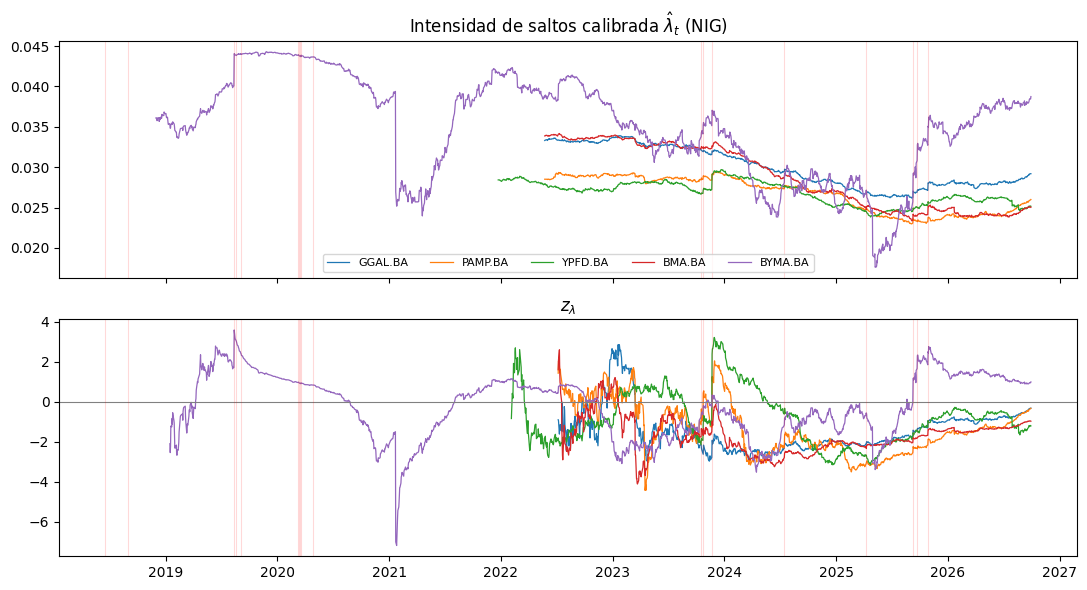

In [10]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(11, 6))
for t, est in res["estimators"].items():
    e = est.dropna(subset=["jump_intensity"])
    axes[0].plot(e.index, e["jump_intensity"], label=t, linewidth=0.9)
    axes[1].plot(e.index, e["z_lambda"], label=t, linewidth=0.9)
axes[0].set_title("Intensidad de saltos calibrada $\\hat\\lambda_t$ (NIG)")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_title("$z_\\lambda$")
axes[0].legend(ncol=5, fontsize=8)
for d in [d for ds in EPISODE_CATALOG.values() for d in ds]:
    for ax in axes:
        ax.axvline(pd.Timestamp(d), color="red", alpha=0.15, linewidth=0.8)
plt.tight_layout()
plt.show()

## Paso 5-7 — Eventos, logit pooled point-in-time y exposición (Sección 4)

**Alineación (corregida).** La exposición del día $t$ se aplica al retorno de $t$, así
que el evento de la fila $t$ usa $r_t,\dots,r_{t+h-1}$ y se conoce al cierre de
$r_{t+h-1}$ (`known_at`). Antes usaba $r_{t+1..t+h}$, desalineado un día.

**Entrenamiento point-in-time (pedido en el feedback de la Entrega #3).** Cada día $t$ se reajusta el logit
pooled (efectos fijos por activo, King-Zeng) con **solo** las filas cuyo `known_at < t`.
Un activo entra al entrenamiento cuando tiene al menos 60 observaciones y 5 eventos
cerrados; el ajuste necesita al menos 20 eventos en total. $\tau_i$ para King-Zeng
también usa información disponible hasta $t$. Los errores Newey-West agrupados por
activo se reportan sobre el último ajuste.

In [11]:
fit = res["fit"]
print("Modo:", fit.mode, "| cov_type:", fit.cov_type_used)
print(f"Último ajuste: {fit.n_obs} filas, {fit.n_events} eventos (tasa {fit.y_bar:.1%})")
pendientes = pd.DataFrame({"Pendiente (último ajuste)": pd.Series(fit.slopes)})
if fit.bse_hac is not None:
    pendientes["Error est. NW"] = fit.bse_hac.reindex(pendientes.index)
    pendientes["z"] = pendientes.iloc[:, 0] / pendientes["Error est. NW"]
pendientes

Modo: walk_forward | cov_type: Newey-West clustered-por-activo (manual), ultimo ajuste
Último ajuste: 6094 filas, 611 eventos (tasa 10.0%)


,Pendiente (último ajuste),Error est. NW,z
z_lambda,0.109017,0.052441,2.078852
z_dlambda,0.016648,0.055238,0.301384
z_lambda:z_dlambda,0.019718,0.011526,1.710700


In [12]:
pd.DataFrame({
    "alpha_i (crudo)": pd.Series(fit.alpha_raw),
    "alpha_i (King-Zeng)": pd.Series(fit.alpha_corrected),
    "tau_i": pd.Series(fit.tau),
})

,alpha_i (crudo),alpha_i (King-Zeng),tau_i
BMA.BA,-2.000694,-2.003608,0.1
BYMA.BA,-2.108729,-2.111643,0.1
GGAL.BA,-2.052802,-2.055716,0.1
PAMP.BA,-2.339940,-2.342853,0.1
YPFD.BA,-2.048043,-2.050957,0.1


### Historia del logit walk-forward

Cómo evolucionan las pendientes y el tamaño de la muestra de entrenamiento a medida
que se cierran eventos. Pendientes que cambian de signo o saltan mucho indican que la
señal no es estable en el tiempo.

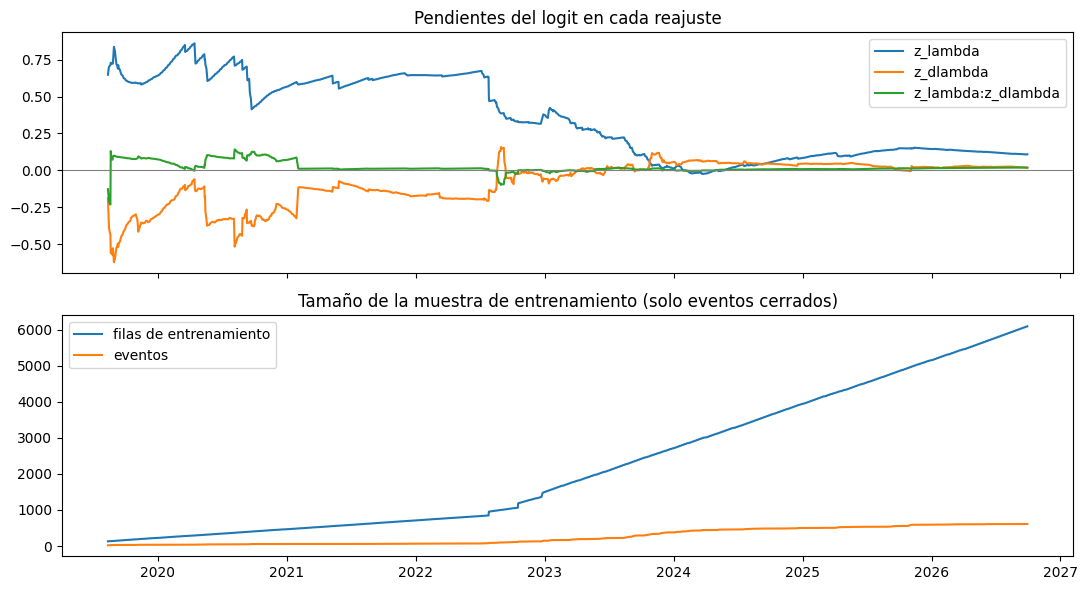

In [13]:
hist = fit.history
if hist is not None and len(hist):
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(11, 6))
    for c in ["z_lambda", "z_dlambda", "z_lambda:z_dlambda"]:
        if c in hist:
            axes[0].plot(hist.index, hist[c], label=c)
    axes[0].axhline(0, color="gray", linewidth=0.8)
    axes[0].set_title("Pendientes del logit en cada reajuste")
    axes[0].legend()
    axes[1].plot(hist.index, hist["n_obs"], label="filas de entrenamiento")
    axes[1].plot(hist.index, hist["n_events"], label="eventos")
    axes[1].set_title("Tamaño de la muestra de entrenamiento (solo eventos cerrados)")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

### ¿La señal está viva? Cobertura y variación por activo

`inicio_exposicion`: primer día con exposición decidida por el modelo;
`episodios_cubiertos`: episodios del catálogo dentro del período evaluable;
`cv_lambda_pct`: coeficiente de variación de $\hat\lambda$ en ese período;
`cambios_exposicion`: cuántas veces la histéresis dejó cambiar la exposición.

In [14]:
res["diagnostics"]

,W_i,estado_W_E,inicio_senal,inicio_exposicion,dias_evaluables,anios_evaluables,episodios_cubiertos,episodios,cv_lambda_pct,cambios_exposicion,exp_min,exp_media,exp_max
activo,,,,,,,,,,,,,
GGAL.BA,1800,estabiliza,2022-07-14,2022-10-18,971,3.85,2,"ciclo_electoral_2023, era_milei_2024_2025",8.05,10,67.8,89.6,95.4
PAMP.BA,1800,estabiliza,2022-07-14,2022-12-26,925,3.67,2,"ciclo_electoral_2023, era_milei_2024_2025",8.02,2,87.0,91.4,94.6
YPFD.BA,1700,estabiliza,2022-02-11,2022-07-27,1026,4.07,2,"ciclo_electoral_2023, era_milei_2024_2025",5.25,8,57.6,86.7,97.5
BMA.BA,1800,estabiliza,2022-07-14,2022-10-18,971,3.85,2,"ciclo_electoral_2023, era_milei_2024_2025",13.25,4,83.4,89.9,95.4
BYMA.BA,350,estabiliza,2019-01-22,2019-08-13,1744,6.92,4,"paso_2019, covid_petroleo_2020, ciclo_electora...",18.23,18,0.2,90.2,99.7


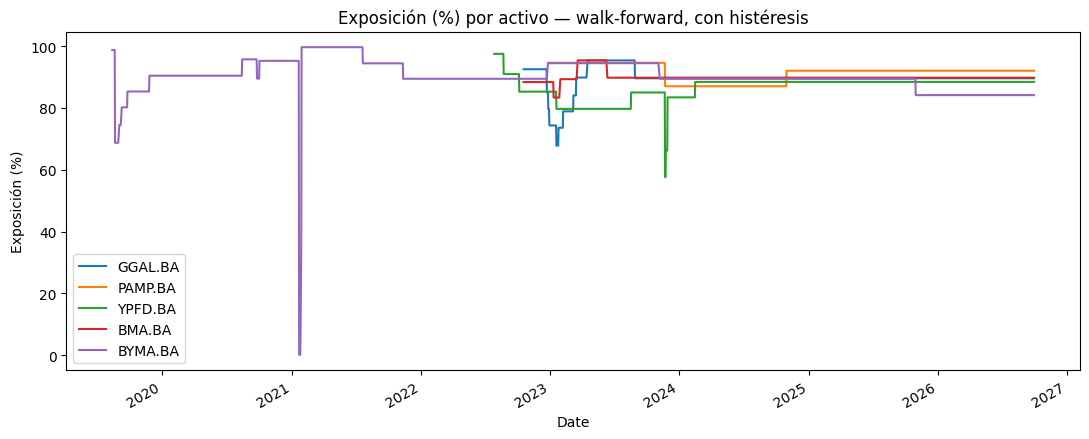

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for t, exp in res["exposures"].items():
    exp.dropna().plot(ax=ax, label=t)
ax.set_title("Exposición (%) por activo — walk-forward, con histéresis")
ax.set_ylabel("Exposición (%)")
ax.legend()
plt.tight_layout()
plt.show()

### Variantes de evento y de $\tau$ (misma ventana)

Con la ventana ya elegida (la calibración NIG sale de la caché, solo se reajusta el
logit), se comparan las definiciones de evento y de $\tau$. Es solo diagnóstico y deja trazada la justificación de la configuración adoptada (horizonte / modelo, ver Paso 2b); la especificación original sigue disponible por configuración.

In [16]:
if COMPARAR_CRITERIOS:
    filas = []
    for ev in EVENT_DEFINITIONS:
        for tm in TAU_METHODS:
            cfg = PipelineConfig(**{**CONFIG.__dict__, "event_definition": ev, "tau_method": tm})
            r_ = run_pipeline(returns_by_asset, cfg, verbose=False, price_data=price_data, cash_rate=CAJA)
            d = r_["diagnostics"]
            f = r_["fit"]
            filas.append({
                "evento": ev, "tau": tm,
                "logit_ajustado": f is not None,
                "activos_con_exposicion": int((d["dias_evaluables"] > 0).sum()),
                "tasa_eventos_panel": r_["panel"]["event"].mean(),
                "n_obs_ultimo_ajuste": f.n_obs if f else 0,
                **{f"pend[{k}]": v for k, v in (f.slopes if f else {}).items()},
                "exp_media_prom": d["exp_media"].mean(),
                "cambios_exposicion_total": d["cambios_exposicion"].sum(),
            })
    tabla_eventos = pd.DataFrame(filas)
    tabla_eventos.to_csv("event_definition_comparison.csv", index=False)
    display(tabla_eventos.round(4))

,evento,tau,logit_ajustado,activos_con_exposicion,tasa_eventos_panel,n_obs_ultimo_ajuste,pend[z_lambda],pend[z_dlambda],pend[z_lambda:z_dlambda],exp_media_prom,cambios_exposicion_total
0,diaria,excedencias,True,5,0.4160,6094,0.1082,-0.0082,0.0111,94.28,24
1,diaria,modelo,True,5,0.4160,6094,0.1082,-0.0082,0.0111,53.18,189
2,horizonte,excedencias,True,5,0.0987,6094,0.1090,0.0166,0.0197,95.00,19
3,horizonte,modelo,True,5,0.0987,6094,0.1090,0.0166,0.0197,89.56,42


## Paso 8 — Cartera, costos y comparadores (Sección 5 + Fase 3)

**Qué cambió respecto de la Entrega #3.** Antes, la cartera promediaba cada día los
retornos de los activos. Eso equivale a **rebalancear a pesos iguales todos los días sin
costo**, y el benchmark además no pagaba la compra inicial. Ahora estrategia y
comparadores pasan por el **mismo** motor (`comparators.simulate_portfolio`):

- cada activo es un bolsillo con posición y caja; entre rebalanceos las posiciones
  **derivan** con los precios;
- se rebalancea entre activos con la frecuencia de `CONFIG.rebalance` (mensual por
  defecto) y cada vez que entra un activo nuevo;
- dentro de un activo solo se opera cuando cambia la exposición objetivo;
- **toda** compra o venta paga el costo por lado, incluida la compra inicial del
  benchmark.

**Costos.** Por unidad de turnover **one-way**: comisión + derecho de mercado (66,55 pb por
lado, con IVA) más **medio** spread de Corwin-Schultz (45,6–62,5 pb según el activo). En total, 112–129 pb por lado (226–258 pb de ida y vuelta).

**Comparadores** (mismos activos y mismas fechas que la estrategia):

| Comparador | Regla | Para qué |
|---|---|---|
| EW 100% | 100% invertido en cada activo | Benchmark pasivo, ahora con compra inicial y rebalanceo con costos |
| Exposición fija (media ex post) | cada activo a la exposición media que tuvo la estrategia | Separa "estar menos invertido" de "elegir cuándo". Usa la media de todo el período: es un diagnóstico, no una regla implementable |
| Vol targeting | $\min(1, \sigma^*_t/\hat\sigma_t)$, con $\hat\sigma_t$ de 60 ruedas y $\sigma^*_t$ = mediana histórica, ambos hasta $t-1$; histéresis de 5 p.p. | Defensa simple que no usa Lévy |
| MA200 | 100% si el precio de $t-1$ supera su media de 200 ruedas; 0% si no | Filtro de tendencia clásico |
| Merval | índice S&P Merval, sin costos | Referencia de mercado |

Tasa de la caja: pase a 1 día del BCRA (proxy de la caución, `macro_data.py`), conocida en $t-1$; la caja de cada
bolsillo devenga intereses todos los días y Sharpe/Sortino se calculan en exceso de esa tasa. Si las
variables macro no están disponibles (`CAJA = None`), la caja rinde 0% y la tasa libre de riesgo es 0,
lo que favorece al benchmark 100% invertido y **no** es la configuración reportable.

Con `RECALIBRATION_STEP = 1` (paso diario) los resultados son los reportables; con un paso mayor
serían preliminares y no reutilizan el caché.

In [17]:
print("Costo por unidad de turnover one-way (pb):")
display(cost_table()[["fijo_por_lado", "medio_spread_medio", "costo_por_lado_medio", "costo_round_trip_medio"]])
print(f"Rebalanceo entre activos: {CONFIG.rebalance}")
res["comparison"].round(4)

Costo por unidad de turnover one-way (pb):


,fijo_por_lado,medio_spread_medio,costo_por_lado_medio,costo_round_trip_medio
GGAL.BA,66.55,46.75,113.30,226.6
PAMP.BA,66.55,55.30,121.85,243.7
YPFD.BA,66.55,45.55,112.10,224.2
BMA.BA,66.55,61.00,127.55,255.1
BYMA.BA,66.55,62.50,129.05,258.1


Rebalanceo entre activos: mensual


,Estrategia,EW 100%,Exposición fija (media ex post),Vol targeting,MA200,Merval (índice)
Retorno anualizado,1.2852,1.3567,1.2823,1.1797,1.1012,0.9528
Volatilidad anualizada,0.4122,0.4581,0.4124,0.3904,0.4059,0.4485
Sharpe,1.1229,1.1203,1.1194,1.0431,0.9273,0.7187
Sortino,1.7916,1.7836,1.7839,1.6304,1.4624,1.0550
Max Drawdown,-0.3606,-0.4145,-0.3596,-0.3820,-0.4051,-0.4870
Calmar,3.5637,3.2729,3.5663,3.0879,2.7183,1.9565
Días,1744.0000,1744.0000,1744.0000,1744.0000,1744.0000,1738.0000
Exposición media,0.9031,1.0000,0.8991,0.8809,0.8640,1.0000
Turnover anual,1.3736,0.9514,0.9038,1.4653,4.6182,0.0000
Costo total (pp),12.1025,8.2203,7.8468,13.0392,39.7052,0.0000


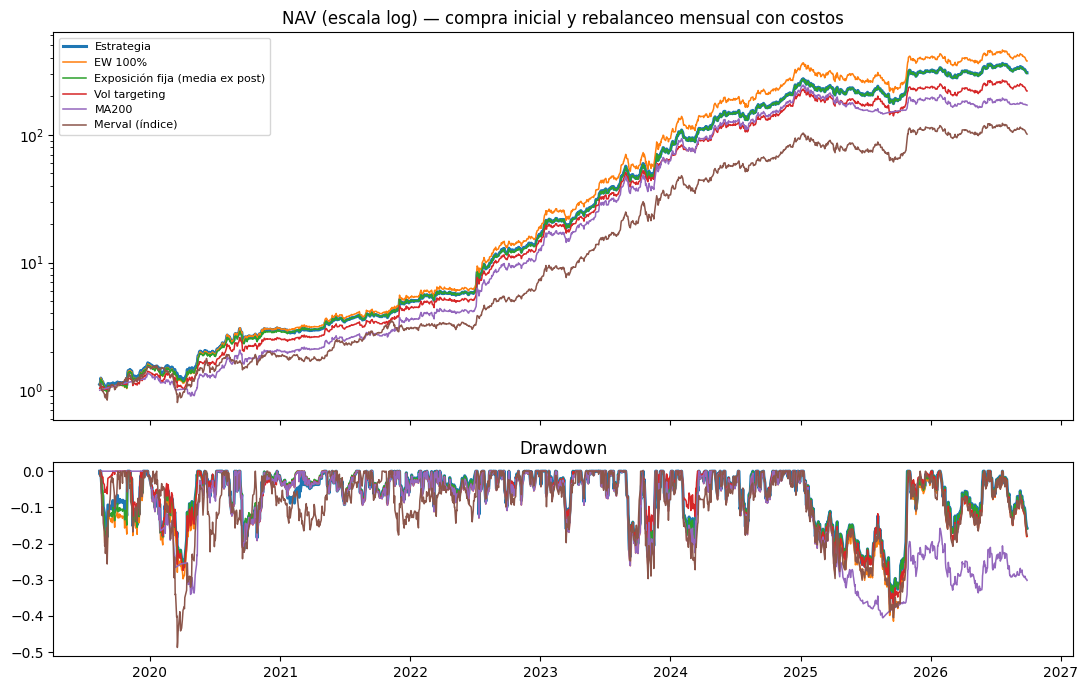

In [18]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(11, 7), gridspec_kw={"height_ratios": [2, 1]})
for name, df in res["portfolios"].items():
    lw = 2.2 if name == "Estrategia" else 1.1
    axes[0].plot(df.index, df["nav"], label=name, linewidth=lw)
    dd = df["nav"] / df["nav"].cummax().clip(lower=1.0) - 1
    axes[1].plot(df.index, dd, label=name, linewidth=lw)
axes[0].set_yscale("log")
axes[0].set_title(f"NAV (escala log) — compra inicial y rebalanceo {CONFIG.rebalance} con costos")
axes[0].legend(fontsize=8)
axes[1].set_title("Drawdown")
plt.tight_layout()
plt.show()

### Resultados por tramo de composición

La cartera no tiene los mismos activos todo el período (con W distintos, cada activo entra en otra fecha). El total mezcla tramos de 1, 2, 4 y 5 activos; esta tabla los separa. Se omiten los tramos de menos de 60 ruedas, que son los de 2 y 4 activos (julio a diciembre de 2022); quedan el de 1 activo (solo BYMA) y el de 5.

In [19]:
por_tramo = res["comparison_by_period"]
por_tramo.pivot_table(index=["tramo", "activos"], columns="cartera",
                      values=["retorno_anual", "max_drawdown"]).round(3)

max_drawdown                                                                                 retorno_anual             \
cartera                              EW 100% Estrategia Exposición fija (media ex post)  MA200 Merval (índice) Vol targeting       EW 100% Estrategia   
tramo                   activos                                                                                                                         
2019-08-13 → 2022-07-26 1             -0.297     -0.265                          -0.264 -0.340          -0.487        -0.274         1.276      1.188   
2022-12-26 → 2026-09-29 5             -0.415     -0.361                          -0.360 -0.405          -0.405        -0.382         1.302      1.250   

                                                                                                      
cartera                         Exposición fija (media ex post)  MA200 Merval (índice) Vol targeting  
tramo                   activos                                                                       
2019-08-13 → 2022-07-26 1                                 1.190  0.977           0.677         1.098  
2022-12-26 → 2026-09-29 5                                 1.256  1.068           1.094         1.123

### Sensibilidad al supuesto de rebalanceo

Estrategia y EW 100% con cada frecuencia de rebalanceo entre activos, más la referencia
de la Entrega #3 (promedio diario de retornos, sin costo). Responde al feedback: cuánto del resultado depende del supuesto de rebalanceo.

In [20]:
sens_rebal = rebalance_sensitivity(res)
sens_rebal.to_csv("rebalance_sensitivity.csv", index=False)
sens_rebal.pivot(index="rebalanceo", columns="cartera",
                 values=["retorno_anual", "sharpe", "max_drawdown", "costo_total_pp"]).round(3)

retorno_anual             sharpe            max_drawdown            costo_total_pp           
cartera                             EW 100% Estrategia EW 100% Estrategia      EW 100% Estrategia        EW 100% Estrategia
rebalanceo                                                                                                                 
E3: promedio diario sin costo         1.372      1.184   1.136      1.015       -0.413     -0.375            NaN        NaN
diario                                1.299      1.224   1.068      1.060       -0.426     -0.372         21.649     25.196
mensual                               1.357      1.285   1.120      1.123       -0.415     -0.361          8.220     12.103
nunca                                 1.355      1.274   1.105      1.086       -0.455     -0.425          3.953      7.929
trimestral                            1.367      1.292   1.130      1.130       -0.415     -0.361          6.421     10.343

## Paso 9 — ¿La estrategia protege? (Fase 4)

Pregunta del feedback de la Entrega #3: si reducir la exposición protege la cartera **cuando la decisión se
toma solo con la información disponible en cada momento**. Todas las carteras de abajo ya
cumplen esa condición (walk-forward) y pasan por el mismo motor de costos.

Se responde con cinco bloques, siguiendo `estabilidad_subperiodos_regimenes.qmd` y
`riesgo_cola_var_es.qmd`:

1. **Segmentación**: dentro/fuera de episodios (±10 ruedas hábiles de cada fecha del
   catálogo) y régimen de volatilidad (vol de 60 ruedas del EW contra su mediana; es una
   clasificación *ex post*, solo para atribuir resultados).
2. **Por episodio y leave-one-episode-out**: ¿la diferencia depende de un solo episodio?
3. **Riesgo de cola**: VaR/ES rolling out-of-sample (252 ruedas, 95% y 99%), Kupiec,
   Christoffersen (razón $\pi_{11}/\pi_{01}$ = cuánto se agrupan las excepciones) y
   cobertura condicional.
4. **Bootstrap estacionario por bloques** (bloque medio de 20 ruedas, 2.000 réplicas),
   pareado por fecha: intervalo de confianza de cada diferencia.
5. **Deflated Sharpe y PBO**: cuánto puede pesar haber elegido la configuración entre las probadas (grilla de 32; 30 con resultado).

El comparador clave es la **exposición fija**: si la estrategia no le gana, lo que protege
es estar menos invertido, no el timing de la señal.

In [21]:
seg = pr.segmented_metrics(res["portfolios"], risk_free_rate=CAJA)
seg.pivot(index="cartera", columns="segmento", values=["sharpe", "max_drawdown", "peor_dia"]).round(3)

sharpe                                           max_drawdown                                      \
segmento                        dentro de episodio fuera de episodio vol alta vol baja dentro de episodio fuera de episodio vol alta vol baja   
cartera                                                                                                                                         
EW 100%                                      0.582             1.289    0.959    1.353             -0.354            -0.261   -0.375   -0.280   
Estrategia                                   0.642             1.275    0.976    1.298             -0.314            -0.236   -0.329   -0.245   
Exposición fija (media ex post)              0.586             1.287    0.960    1.351             -0.314            -0.233   -0.328   -0.245   
MA200                                        0.123             1.099    0.694    1.326             -0.276            -0.404   -0.345   -0.271   
Merval (índice)                              0.471             0.841    0.717    0.698             -0.441            -0.272   -0.435   -0.313   
Vol targeting                                0.168             1.248    0.843    1.318             -0.344            -0.230   -0.340   -0.280   

                                          peor_dia                                      
segmento                        dentro de episodio fuera de episodio vol alta vol baja  
cartera                                                                                 
EW 100%                                     -0.157            -0.093   -0.157   -0.072  
Estrategia                                  -0.141            -0.089   -0.141   -0.062  
Exposición fija (media ex post)             -0.141            -0.084   -0.141   -0.065  
MA200                                       -0.118            -0.093   -0.118   -0.072  
Merval (índice)                             -0.145            -0.097   -0.145   -0.097  
Vol targeting                               -0.156            -0.092   -0.156   -0.068

In [22]:
por_episodio = pr.per_episode_table(res["portfolios"])
por_episodio.pivot(index=["episodio", "desde", "hasta"], columns="cartera",
                   values=["retorno_acumulado", "max_drawdown"]).round(3)

retorno_acumulado                                                                                 max_drawdown  \
cartera                                              EW 100% Estrategia Exposición fija (media ex post)  MA200 Merval (índice) Vol targeting      EW 100%   
episodio             desde      hasta                                                                                                                       
ciclo_electoral_2023 2023-09-29 2023-12-05             0.535      0.492                           0.503  0.535           0.522         0.416       -0.260   
covid_petroleo_2020  2020-02-20 2020-05-13             0.076      0.076                           0.076 -0.099          -0.014         0.039       -0.248   
era_milei_2024_2025  2024-06-28 2025-11-10             1.025      1.027                           1.031  0.445           0.805         0.881       -0.415   
paso_2019            2019-08-13 2019-09-17             0.071      0.116                           0.071  0.069           0.095         0.070       -0.235   

                                                                                                                            
cartera                                    Estrategia Exposición fija (media ex post)  MA200 Merval (índice) Vol targeting  
episodio             desde      hasta                                                                                       
ciclo_electoral_2023 2023-09-29 2023-12-05     -0.237                          -0.234 -0.260          -0.297        -0.183  
covid_petroleo_2020  2020-02-20 2020-05-13     -0.224                          -0.223 -0.251          -0.433        -0.246  
era_milei_2024_2025  2024-06-28 2025-11-10     -0.361                          -0.360 -0.405          -0.405        -0.382  
paso_2019            2019-08-13 2019-09-17     -0.181                          -0.214  0.000          -0.256        -0.063

In [23]:
loo_ew = pr.leave_one_episode_out(res["portfolios"], versus="EW 100%", risk_free_rate=CAJA)
loo_fija = pr.leave_one_episode_out(res["portfolios"], versus="Exposición fija (media ex post)", risk_free_rate=CAJA)
display(loo_ew.round(4))
loo_fija.round(4)

,episodios,días,sharpe_estrategia,sharpe_EW 100%,retorno_medio_estrategia,retorno_medio_EW 100%,dif_retorno_medio_diario,peor_dia_estrategia,peor_dia_EW 100%
0,todos,212,0.6418,0.5818,0.0038,0.0038,-0.0000,-0.1410,-0.1572
1,sin paso_2019,187,0.5977,0.6091,0.0036,0.0039,-0.0002,-0.1410,-0.1572
2,sin covid_petroleo_2020,163,0.8601,0.7840,0.0049,0.0050,-0.0001,-0.1410,-0.1572
3,sin ciclo_electoral_2023,168,0.1763,0.0694,0.0021,0.0018,0.0002,-0.1410,-0.1572
4,sin era_milei_2024_2025,118,0.9773,0.8859,0.0051,0.0051,-0.0001,-0.0959,-0.1072


,episodios,días,sharpe_estrategia,sharpe_Exposición fija (media ex post),retorno_medio_estrategia,retorno_medio_Exposición fija (media ex post),dif_retorno_medio_diario,peor_dia_estrategia,peor_dia_Exposición fija (media ex post)
0,todos,212,0.6418,0.5861,0.0038,0.0037,0.0001,-0.1410,-0.1407
1,sin paso_2019,187,0.5977,0.6184,0.0036,0.0037,-0.0001,-0.1410,-0.1407
2,sin covid_petroleo_2020,163,0.8601,0.7893,0.0049,0.0047,0.0002,-0.1410,-0.1407
3,sin ciclo_electoral_2023,168,0.1763,0.0822,0.0021,0.0019,0.0002,-0.1410,-0.1407
4,sin era_milei_2024_2025,118,0.9773,0.8706,0.0051,0.0048,0.0002,-0.0959,-0.0957


In [24]:
cola = pr.tail_risk_table(res["portfolios"])
cola[["cartera", "nivel", "VaR_medio", "ES_medio", "ES_empirico", "tasa_excepciones",
      "kupiec_p", "christoffersen_p", "razon_pi11_pi01", "cobertura_condicional_p"]].round(4)

,cartera,nivel,VaR_medio,ES_medio,ES_empirico,tasa_excepciones,kupiec_p,christoffersen_p,razon_pi11_pi01,cobertura_condicional_p
0,Estrategia,0.95,0.0354,0.0478,0.0489,0.0503,0.9621,0.2621,1.6417,0.5326
1,Estrategia,0.99,0.0519,0.0671,0.0734,0.0154,0.0515,0.0043,9.5739,0.0025
2,EW 100%,0.95,0.0394,0.0531,0.0549,0.0496,0.9431,0.1001,2.0006,0.2582
3,EW 100%,0.99,0.0576,0.0744,0.0822,0.0161,0.0299,0.0056,8.7321,0.0020
4,Exposición fija (media ex post),0.95,0.0352,0.0475,0.0492,0.0489,0.8488,0.0880,2.0602,0.2290
5,Exposición fija (media ex post),0.99,0.0514,0.0667,0.0739,0.0161,0.0299,0.0056,8.7321,0.0020
6,Vol targeting,0.95,0.0342,0.0471,0.0474,0.0529,0.6045,0.3761,1.4690,0.5910
7,Vol targeting,0.99,0.0500,0.0670,0.0717,0.0188,0.0024,0.1097,4.0192,0.0028
8,MA200,0.95,0.0378,0.0501,0.0506,0.0509,0.8683,0.0499,2.1904,0.1443
9,MA200,0.99,0.0558,0.0659,0.0715,0.0161,0.0299,0.0056,8.7321,0.0020


### Bootstrap: ¿las diferencias son distinguibles del azar?

`diferencia` = estrategia − comparador. En `max_drawdown`, positivo significa que la
estrategia cae menos. `p_dif<=0` es la proporción de réplicas en que la estrategia **no**
supera al comparador; un valor chico (< 0,05) indica una ventaja distinguible del azar en esa métrica (p-valor unilateral, sin corrección por comparaciones múltiples).

In [25]:
boot = pr.bootstrap_table(res["portfolios"], risk_free=CAJA)
boot.round(4)

,comparador_nombre,métrica,estrategia,comparador,diferencia,IC95_inf,IC95_sup,p_dif<=0
0,EW 100%,sharpe,1.1229,1.1203,0.0026,-0.0513,0.0503,0.4460
1,EW 100%,retorno_anual,1.2852,1.3567,-0.0715,-0.2216,0.0147,0.9440
2,EW 100%,max_drawdown,-0.3606,-0.4145,0.0539,0.0128,0.0794,0.0045
3,EW 100%,calmar,3.5637,3.2729,0.2908,-0.1488,0.7916,0.0640
4,Exposición fija (media ex post),sharpe,1.1229,1.1194,0.0036,-0.0508,0.0536,0.4225
5,Exposición fija (media ex post),retorno_anual,1.2852,1.2823,0.0029,-0.0479,0.0495,0.4355
6,Exposición fija (media ex post),max_drawdown,-0.3606,-0.3596,-0.0011,-0.0294,0.0293,0.5715
7,Exposición fija (media ex post),calmar,3.5637,3.5663,-0.0026,-0.3942,0.5068,0.4565
8,Vol targeting,sharpe,1.1229,1.0431,0.0798,-0.0497,0.2190,0.1120
9,Vol targeting,retorno_anual,1.2852,1.1797,0.1054,-0.0180,0.2801,0.0490


### Deflated Sharpe y PBO (sobreajuste por selección de configuración)

Se corre la estrategia para las 32 combinaciones definidas (8 criterios de $W$ × 4 variantes
de evento/$\tau$; 30 con resultados), reutilizando las ventanas de `window_criteria_comparison.csv` y la caché
del NIG. Para que la grilla sea viable, el logit se reajusta cada 5 ruedas (solo en esta
evaluación). La primera vez tarda (del orden de media hora o más); después se lee de
`config_grid_returns_macro.csv`.

- **DSR**: probabilidad de que el Sharpe verdadero de la configuración elegida supere al máximo que se esperaría por azar entre las pruebas. Por encima de 0,95 es la referencia habitual de que el Sharpe resiste la selección; valores menores indican evidencia más débil.
- **PBO**: probabilidad de que la mejor configuración *in-sample* quede por debajo de la
  mediana *out-of-sample*. Cerca de 0,5 = la elección no tiene valor predictivo; cerca de
  0 = la mejor configuración se sostiene.

Ambos se calculan sobre las **fechas comunes** de las configuraciones con al menos 2 años
de historia: comparar Sharpes de períodos distintos (de 48 días a 7 años) inflaría el
umbral del DSR. La última tabla muestra la sensibilidad a esa exigencia.

In [26]:
import os
ELEGIDA = f"{CONFIG.window_criterion}/{CONFIG.window_combine}|{CONFIG.event_definition}|{CONFIG.tau_method}"
if os.path.exists(f"config_grid_returns{SUF}.csv"):
    grilla = pd.read_csv(f"config_grid_returns{SUF}.csv", index_col=0, parse_dates=True)
elif CORRER_GRILLA and os.path.exists("window_criteria_comparison.csv"):
    ventanas = pr.windows_from_criteria_table(pd.read_csv("window_criteria_comparison.csv"))
    grilla = pr.run_configuration_grid(returns_by_asset, ventanas, refit_step=5, price_data=price_data,
                                       cash_rate=CAJA, recalibration_step=RECALIBRATION_STEP,
                                       rebalance=CONFIG.rebalance, cost_mode=CONFIG.cost_mode)
    grilla.to_csv(f"config_grid_returns{SUF}.csv")
else:
    grilla = None
    print("Grilla omitida: hace falta window_criteria_comparison.csv (sección 2a) y CORRER_GRILLA = True.")

if grilla is not None:
    sobreajuste = pr.overfitting_summary(grilla, ELEGIDA, risk_free=CAJA)
    display(pd.Series(sobreajuste["dsr"]).to_frame("Deflated Sharpe").round(4))
    display(pd.Series(sobreajuste["pbo"]).to_frame("PBO"))
    display(sobreajuste["sharpe_anual_por_config"].round(3).to_frame("Sharpe anual (refit cada 5)"))
    # Sensibilidad: qué configuraciones entran según la historia mínima exigida
    sens_dsr = pd.DataFrame([
        {"min_dias": md, "configs": o["pbo"]["configs_en_PBO"], "fechas_comunes": o["pbo"]["fechas_comunes"],
         "SR_elegida": o["dsr"]["sharpe_anual"], "SR0": o["dsr"]["SR0_anual"], "DSR": o["dsr"]["DSR"],
         "PBO": o["pbo"]["PBO"]}
        for md in (252, 504, 756) for o in [pr.overfitting_summary(grilla, ELEGIDA, min_days=md, risk_free=CAJA)]
    ])
    sens_dsr.to_csv("fase4_dsr_pbo_sensibilidad.csv", index=False)
    display(sens_dsr.round(3))

  estandarizado/max|diaria|excedencias: 971 días
  estandarizado/max|diaria|modelo: 971 días
  estandarizado/max|horizonte|excedencias: 925 días
  estandarizado/max|horizonte|modelo: 925 días
  estandarizado/suma|diaria|excedencias: 736 días
  estandarizado/suma|diaria|modelo: 736 días
  estandarizado/suma|horizonte|excedencias: 724 días
  estandarizado/suma|horizonte|modelo: 724 días
  estimadores/max|diaria|excedencias: 1809 días
  estimadores/max|diaria|modelo: 1809 días
  estimadores/max|horizonte|excedencias: 1744 días
  estimadores/max|horizonte|modelo: 1744 días
  estimadores/suma|diaria|excedencias: 1591 días
  estimadores/suma|diaria|modelo: 1591 días
  estimadores/suma|horizonte|excedencias: 1474 días
  estimadores/suma|horizonte|modelo: 1474 días
  parametros/max|diaria|excedencias: 271 días
  parametros/max|diaria|modelo: 271 días
  parametros/max|horizonte|excedencias: 233 días
  parametros/max|horizonte|modelo: 233 días
  parametros/suma|diaria|excedencias: 52 días
  para

,Deflated Sharpe
T,721.0000
N_pruebas,30.0000
sharpe_diario,0.0433
sharpe_anual,0.6880
SR0_diario,0.0081
SR0_anual,0.1286
asimetria,0.9200
curtosis,11.7754
PSR_vs_0,0.8817
DSR,0.8321


,PBO
PBO,0.348951
N_config,20
T,721
combinaciones,12870
logit_mediano,0.485508
pendiente_IS_OOS,-0.975804
configs_en_PBO,20
fechas_comunes,2023-10-25 → 2026-09-29


,Sharpe anual (refit cada 5)
estimadores/max|horizonte|modelo,1.118
estimadores/max|horizonte|excedencias,1.107
estimadores/suma|diaria|excedencias,1.031
estandarizado/max|diaria|modelo,1.026
estimadores/max|diaria|excedencias,1.021
estandarizado/max|diaria|excedencias,1.007
estandarizado/max|horizonte|modelo,0.963
estandarizado/max|horizonte|excedencias,0.961
estimadores/suma|diaria|modelo,0.920
estimadores/max|diaria|modelo,0.891


,min_dias,configs,fechas_comunes,SR_elegida,SR0,DSR,PBO
0,252,26,2025-09-01 → 2026-09-29,0.416,0.129,0.619,0.716
1,504,20,2023-10-25 → 2026-09-29,0.688,0.129,0.832,0.349
2,756,12,2022-12-26 → 2026-09-29,0.913,0.130,0.936,0.476


In [27]:
# Guardar las tablas de la Fase 4
seg.to_csv("fase4_segmentacion.csv", index=False)
por_episodio.to_csv("fase4_por_episodio.csv", index=False)
loo_ew.to_csv("fase4_leave_one_out_vs_EW.csv", index=False)
loo_fija.to_csv("fase4_leave_one_out_vs_fija.csv", index=False)
cola.to_csv("fase4_riesgo_cola.csv", index=False)
boot.to_csv("fase4_bootstrap.csv", index=False)
if grilla is not None:
    pd.concat({"DSR": pd.Series(sobreajuste["dsr"]), "PBO": pd.Series(sobreajuste["pbo"])}).to_csv("fase4_dsr_pbo.csv")
    sobreajuste["sharpe_anual_por_config"].to_csv("fase4_sharpe_por_config.csv")
print("Tablas de la Fase 4 guardadas (fase4_*.csv).")

Tablas de la Fase 4 guardadas (fase4_*.csv).


## Paso 10 — Costos variables, liquidez y piso por drawdown (Fase 5)

1. **Costo variable.** Spread de Corwin-Schultz diario (High/Low sin ajustar, variante
   backward-looking), suavizado con la media de 20 ruedas y conocido en $t-1$. Costo por
   lado = 66,55 pb + medio spread. En promedio coincide con el costo constante; lo que
   cambia es que **sube en los días de estrés**, que es cuando la estrategia opera. Es el
   caso base desde esta fase (`cost_mode="variable"`).
2. **Tope de 10% del ADV.** Con un AUM hipotético de 500 millones de ARS se
   cuentan las órdenes que superarían el 10% del ADV de 20 ruedas. Como el AUM es un
   supuesto arbitrario (y nominal en pesos), se interpreta como el valor de la cartera **en
   cada fecha**, y se reporta además la **capacidad**: el valor máximo de cartera, en pesos
   de la fecha de la orden, con el que el 95% de las órdenes respeta el tope. Es un
   diagnóstico, no se fuerza en el backtest.
3. **Piso por drawdown.** Techo de exposición $=\max(E_{min}, 100\% - \kappa(|DD|-D_{max}))$
   cuando el precio cae más de $D_{max}$ desde su máximo de 252 ruedas. Se compara con y sin
   el piso ($D_{max}=20\%$, $\kappa=2$, $E_{min}=25\%$); la grilla de parámetros va en la
   Fase 6.

activo,BMA.BA,BYMA.BA,GGAL.BA,PAMP.BA,YPFD.BA
episodio,,,,,
ciclo_electoral_2023,1.90,1.27,1.46,1.32,1.44
covid_petroleo_2020,1.73,1.15,0.99,0.95,1.19
crisis_cambiaria_2018,0.75,1.07,1.15,1.12,1.77
era_milei_2024_2025,1.21,1.22,1.54,1.27,1.46
paso_2019,1.98,1.70,2.05,1.95,1.67


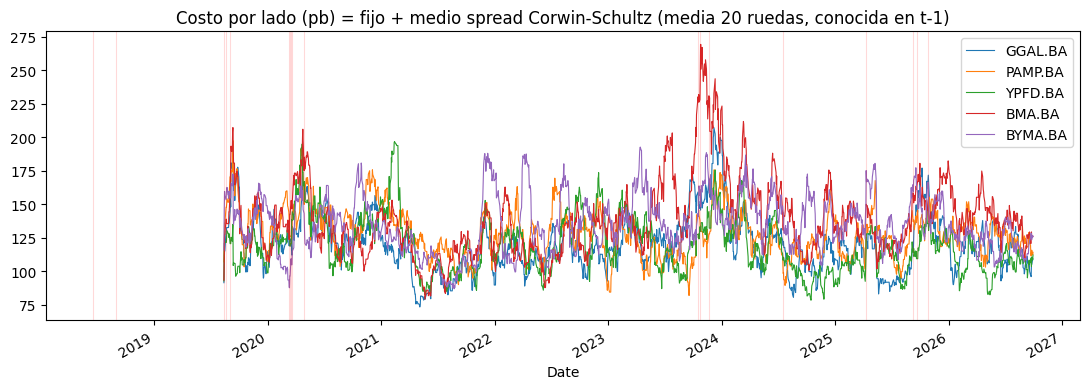

,mean,50%,max
GGAL.BA,113.3,110.9,207.2
PAMP.BA,121.8,120.4,197.5
YPFD.BA,112.1,108.7,196.8
BMA.BA,127.5,123.0,269.3
BYMA.BA,129.0,128.1,192.7


In [28]:
# Validación de sentido del estimador: ¿el spread se ensancha en los episodios?
sp_ep = lq.spread_by_episode(price_data)
display(sp_ep.pivot(index="episodio", columns="activo", values="razon").round(2))

costo_var = res["cost_used"] if isinstance(res["cost_used"], pd.DataFrame) else None
if costo_var is not None:
    fig, ax = plt.subplots(figsize=(11, 4))
    costo_var.loc[res["portfolios"]["Estrategia"].index[0]:].plot(ax=ax, linewidth=0.8)
    for d in [d for ds in EPISODE_CATALOG.values() for d in ds]:
        ax.axvline(pd.Timestamp(d), color="red", alpha=0.15, linewidth=0.8)
    ax.set_title("Costo por lado (pb) = fijo + medio spread Corwin-Schultz (media 20 ruedas, conocida en t-1)")
    plt.tight_layout()
    plt.show()
    display(costo_var.describe().T[["mean", "50%", "max"]].round(1))

In [29]:
sens_costo = lq.cost_sensitivity(res, price_data)
sens_costo.pivot(index="costo", columns="cartera",
                 values=["retorno_anual", "sharpe", "max_drawdown", "costo_total_pp"]).round(3)

retorno_anual                                             sharpe                                            max_drawdown             \
cartera        EW 100% Estrategia Exposición fija (media ex post) EW 100% Estrategia Exposición fija (media ex post)      EW 100% Estrategia   
costo                                                                                                                                          
medio            1.357      1.286                           1.283   1.121      1.124                           1.120       -0.415     -0.361   
p95              1.327      1.244                           1.255   1.094      1.079                           1.091       -0.418     -0.364   
variable         1.357      1.285                           1.282   1.120      1.123                           1.119       -0.415     -0.361   

                                         costo_total_pp                                             
cartera  Exposición fija (media ex post)        EW 100% Estrategia Exposición fija (media ex post)  
costo                                                                                               
medio                             -0.360          8.023     11.774                           7.645  
p95                               -0.363         16.889     24.632                          16.092  
variable                          -0.360          8.220     12.103                           7.847

In [30]:
if res["liquidity"]:
    print(f"AUM supuesto (valor de la cartera en cada fecha): ARS {CONFIG.aum_ars:,.0f} | "
          f"tope: {CONFIG.adv_cap_pct:.0%} del ADV_20 | capacidad en pesos de cada fecha")
    display(res["liquidity"]["por_activo"].round(4))
    display(res["liquidity"]["por_anio"].round(4))

AUM supuesto (valor de la cartera en cada fecha): ARS 500,000,000 | tope: 10% del ADV_20 | capacidad en pesos de cada fecha


,ordenes,violaciones,pct_violaciones,participacion_mediana,participacion_max,capacidad_p5_ARS,capacidad_min_ARS
GGAL.BA,59.0,1.0,0.0169,0.0007,0.3537,2.815959e+09,1.413765e+08
PAMP.BA,48.0,1.0,0.0208,0.0011,0.4052,2.364041e+09,1.233807e+08
YPFD.BA,61.0,3.0,0.0492,0.0006,1.2014,7.575691e+08,4.161846e+07
BMA.BA,53.0,3.0,0.0566,0.0030,1.9565,6.692255e+08,2.555645e+07
BYMA.BA,105.0,35.0,0.3333,0.0283,34.4007,1.027861e+07,1.453459e+06


,ordenes,violaciones,pct_violaciones,participacion_mediana,participacion_max,capacidad_p5_ARS,capacidad_min_ARS
2019,9.0,7.0,0.7778,0.7868,13.9714,9.135845e+06,3.578752e+06
2020,15.0,9.0,0.6000,0.2494,0.8204,6.637145e+07,6.094662e+07
2021,19.0,7.0,0.3684,0.0535,34.4007,1.928568e+06,1.453459e+06
2022,37.0,19.0,0.5135,0.1176,7.5305,2.315983e+07,6.639706e+06
2023,78.0,1.0,0.0128,0.0073,0.1633,1.015524e+09,3.062173e+08
2024,62.0,0.0,0.0000,0.0012,0.0283,3.846142e+09,1.769253e+09
2025,61.0,0.0,0.0000,0.0005,0.0041,1.438601e+10,1.234262e+10
2026,45.0,0.0,0.0000,0.0005,0.0085,1.089011e+10,5.866359e+09


In [31]:
cfg_piso = PipelineConfig(**{**CONFIG.__dict__, "drawdown_floor": lq.DEFAULT_DRAWDOWN_FLOOR})
res_piso = run_pipeline(returns_by_asset, cfg_piso, verbose=False, merval_log_returns=merval,
                        price_data=price_data, cash_rate=CAJA)
piso = pd.concat({
    "Estrategia": res["comparison"]["Estrategia"],
    "Estrategia + piso DD": res_piso["comparison"]["Estrategia"],
    "EW 100%": res["comparison"]["EW 100%"],
}, axis=1)
display(piso.round(4))
boot_piso = pr.bootstrap_differences(res_piso["portfolios"]["Estrategia"]["net_return"],
                                     res["portfolios"]["Estrategia"]["net_return"], risk_free=CAJA)
boot_piso.round(4)

,Estrategia,Estrategia + piso DD,EW 100%
Retorno anualizado,1.2852,1.1796,1.3567
Volatilidad anualizada,0.4122,0.3943,0.4581
Sharpe,1.1229,1.0359,1.1203
Sortino,1.7916,1.6300,1.7836
Max Drawdown,-0.3606,-0.3483,-0.4145
Calmar,3.5637,3.3864,3.2729
Días,1744.0000,1744.0000,1744.0000
Exposición media,0.9031,0.8792,1.0000
Turnover anual,1.3736,1.8555,0.9514
Costo total (pp),12.1025,16.7016,8.2203


,métrica,estrategia,comparador,diferencia,IC95_inf,IC95_sup,p_dif<=0
0,sharpe,1.0359,1.1229,-0.0870,-0.1708,-0.0217,0.9950
1,retorno_anual,1.1796,1.2852,-0.1056,-0.2134,-0.0330,0.9995
2,max_drawdown,-0.3483,-0.3606,0.0123,-0.0356,0.0356,0.4190
3,calmar,3.3864,3.5637,-0.1773,-0.9387,0.2744,0.8925


In [32]:
sp_ep.to_csv("fase5_spread_por_episodio.csv", index=False)
sens_costo.to_csv("fase5_sensibilidad_costo.csv", index=False)
piso.to_csv("fase5_piso_drawdown.csv")
boot_piso.to_csv("fase5_piso_drawdown_bootstrap.csv", index=False)
print("Tablas de la Fase 5 guardadas (fase5_*.csv); ADV en adv_por_activo.csv / adv_por_anio.csv.")

Tablas de la Fase 5 guardadas (fase5_*.csv); ADV en adv_por_activo.csv / adv_por_anio.csv.


## Paso 11 — Sensibilidad a los supuestos (Fase 6)

Aclaración general del feedback: *probar cuánto dependen los resultados de los supuestos*.

**Qué se mira.** Además del Sharpe, cada variante reporta:
- `dif_mdd_vs_EW` > 0: cae menos que el benchmark (¿protege?);
- `dif_sharpe_vs_fija`: Sharpe menos el de una exposición fija a la media de **esa**
  variante (¿aporta el timing?). La conclusión de la Fase 4 es robusta si esta columna se
  queda cerca de 0 en todas las variantes.

**Parámetros** (uno por vez, el resto en la configuración base):

| Parámetro | Valores | Tipo |
|---|---|---|
| u (umbral de salto, u = k·σ) | 1,5 / 1,75 / **2** / 2,5 / 3 | señal |
| h (horizonte del evento) | 3 / **5** / 7 / 10 | señal |
| criterio de W | **estimadores/max**, estimadores/suma, estandarizado/max, sin_mu/max | señal |
| banda de histéresis (p.p.) | 0 / 2 / **5** / 8 / 12 | cartera |
| costo | solo fijo / medio / **variable** / p95 / 350 pb | cartera |
| rebalanceo | diario / **mensual** / trimestral / nunca | cartera |

Los de señal reajustan el logit (con W fijos y el NIG desde la caché: u y h se derivan de
los mismos parámetros calibrados). Los de cartera solo re-simulan la cartera. Para que la
grilla sea viable, **todas** las variantes (incluida la base) reajustan el logit cada 5
ruedas; por eso la fila `base` puede diferir levemente de la corrida principal. La primera
vez tarda (del orden de 15–30 minutos); después se lee de `fase6_ofat_macro.csv`.

In [33]:
import os
if os.path.exists(f"fase6_ofat{SUF}.csv"):
    ofat = pd.read_csv(f"fase6_ofat{SUF}.csv")
elif CORRER_SENSIBILIDAD:
    tabla_w = pd.read_csv("window_criteria_comparison.csv") if os.path.exists("window_criteria_comparison.csv") else None
    ofat = se.run_ofat(res, returns_by_asset, price_data=price_data, windows_table=tabla_w, refit_step=5)
    ofat.to_csv(f"fase6_ofat{SUF}.csv", index=False)
else:
    ofat = None
if ofat is not None:
    display(ofat[["parametro", "valor", "sharpe", "max_drawdown", "exposicion_media", "costo_total_pp",
                  "dif_sharpe_vs_EW", "dif_mdd_vs_EW", "dif_sharpe_vs_fija", "dif_mdd_vs_fija"]].round(4))

  {}: 24 s
  {'u_multiplier': 1.5}: 524 s
  {'u_multiplier': 1.75}: 526 s
  {'u_multiplier': 2.5}: 524 s
  {'u_multiplier': 3.0}: 529 s
  {'horizon': 3}: 536 s
  {'horizon': 7}: 530 s
  {'horizon': 10}: 530 s
  {'windows': {'GGAL.BA': 2047, 'PAMP.BA': 2047, 'YPFD.BA': 1919, 'BMA.BA': 2035, 'BYMA.BA': 574}, 'window_criterion': 'estimadores', 'window_combine': 'suma'}: 18 s
  {'windows': {'GGAL.BA': 1800, 'PAMP.BA': 1800, 'YPFD.BA': 2200, 'BMA.BA': 1800, 'BYMA.BA': 1800}, 'window_criterion': 'estandarizado', 'window_combine': 'max'}: 14 s
  {'windows': {'GGAL.BA': 2050, 'PAMP.BA': 2500, 'YPFD.BA': 2100, 'BMA.BA': 2050, 'BYMA.BA': 1850}, 'window_criterion': 'sin_mu', 'window_combine': 'max'}: 11 s


,parametro,valor,sharpe,max_drawdown,exposicion_media,costo_total_pp,dif_sharpe_vs_EW,dif_mdd_vs_EW,dif_sharpe_vs_fija,dif_mdd_vs_fija
0,base,base,1.1180,-0.3568,0.9017,12.1938,-0.0013,0.0578,0.0001,0.0004
1,u_multiplier,1.5,1.1082,-0.3646,0.9079,11.2271,-0.0111,0.0499,-0.0103,-0.0023
2,u_multiplier,1.75,1.1178,-0.3637,0.9076,11.8417,-0.0015,0.0508,-0.0004,-0.0013
3,u_multiplier,2.5,1.1432,-0.3568,0.9020,9.7868,0.0239,0.0577,0.0239,-0.0013
4,u_multiplier,3.0,1.1416,-0.3575,0.9018,9.8654,0.0223,0.0570,0.0224,-0.0021
5,horizon,3,1.0247,-0.3698,0.9100,12.7742,-0.0170,0.0447,-0.0182,-0.0040
6,horizon,7,1.1075,-0.3589,0.9005,11.2807,0.0255,0.0557,0.0240,-0.0002
7,horizon,10,1.0869,-0.3624,0.9030,10.0796,0.0245,0.0521,0.0272,-0.0072
8,criterio_W,estimadores/suma,0.8084,-0.3643,0.8843,23.2197,-0.0496,0.0502,-0.0557,-0.0070
9,criterio_W,estandarizado/max,0.9627,-0.3633,0.8941,6.4313,-0.0063,0.0552,-0.0116,-0.0016


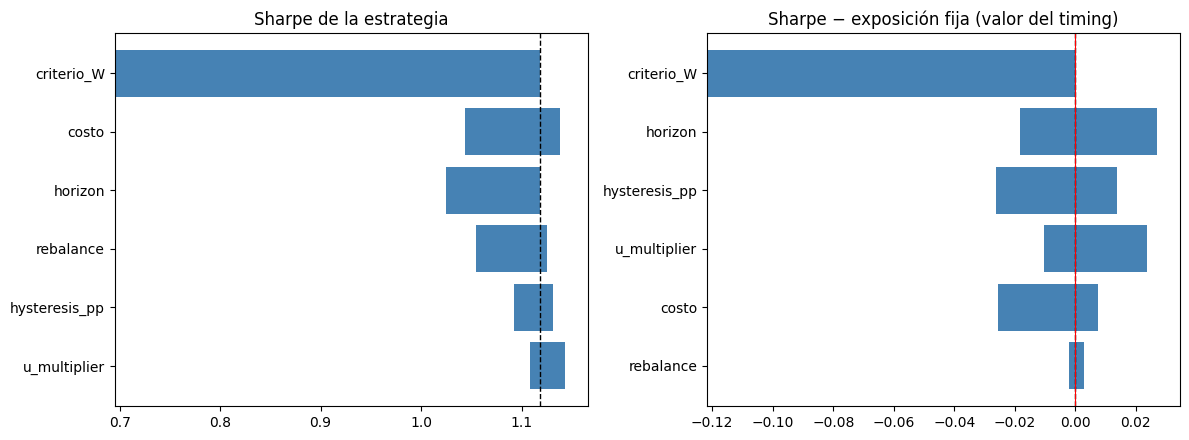

,parametro,min,max,rango,valor_min,valor_max
0,criterio_W,0.6951,1.1180,0.4229,sin_mu/max,estandarizado/max
1,costo,1.0438,1.1385,0.0947,350 pb,solo fijo
2,horizon,1.0247,1.1180,0.0933,3,7
3,rebalance,1.0550,1.1256,0.0705,diario,trimestral
4,hysteresis_pp,1.0924,1.1316,0.0392,0.0,8.0
5,u_multiplier,1.1082,1.1432,0.0349,1.5,2.5


,parametro,min,max,rango,valor_min,valor_max
0,criterio_W,-0.1217,0.0001,0.1217,sin_mu/max,estandarizado/max
1,horizon,-0.0182,0.0272,0.0454,3,10
2,hysteresis_pp,-0.0262,0.0137,0.0399,0.0,12.0
3,u_multiplier,-0.0103,0.0239,0.0342,1.5,2.5
4,costo,-0.0254,0.0076,0.0331,350 pb,solo fijo
5,rebalance,-0.0020,0.0030,0.0050,nunca,trimestral


In [34]:
if ofat is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, metric, titulo in [(axes[0], "sharpe", "Sharpe de la estrategia"),
                               (axes[1], "dif_sharpe_vs_fija", "Sharpe − exposición fija (valor del timing)")]:
        tor = se.tornado_table(ofat, metric)
        ax.barh(tor["parametro"], tor["max"] - tor["min"], left=tor["min"], color="steelblue")
        ax.axvline(tor.attrs["base"], color="black", linestyle="--", linewidth=1)
        if metric.startswith("dif"):
            ax.axvline(0, color="red", linewidth=0.8)
        ax.invert_yaxis()
        ax.set_title(titulo)
    plt.tight_layout()
    plt.show()
    tornado_sharpe = se.tornado_table(ofat, "sharpe")
    tornado_timing = se.tornado_table(ofat, "dif_sharpe_vs_fija")
    display(tornado_sharpe.round(4))
    display(tornado_timing.round(4))

### Interacción entre los dos parámetros más sensibles

Grilla factorial completa entre los dos parámetros de mayor rango de Sharpe entre los que admiten una grilla de valores (costo y horizonte del evento; el criterio de W, que es el de mayor rango, se evalúa solo un parámetro a la vez). Si el patrón varía solo a lo largo de un eje, los efectos son independientes y el
análisis de un parámetro por vez alcanza; si es diagonal o irregular, hay interacción.

Factorial: costo × horizon
  señal {'horizon': 3}
  señal {'horizon': 5}
  señal {'horizon': 7}
  señal {'horizon': 10}


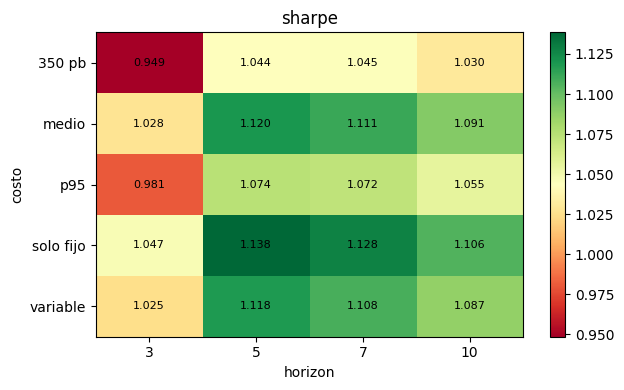

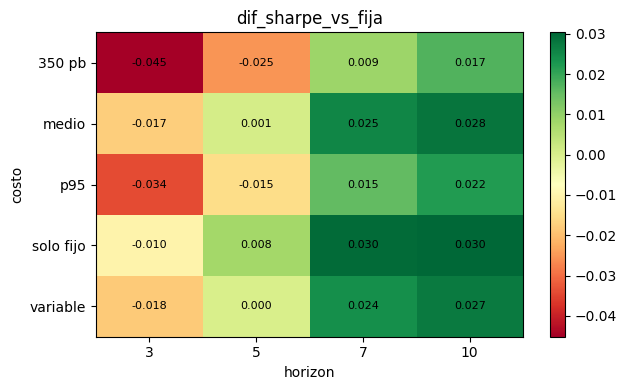

In [35]:
VALORES = {**se.SIGNAL_PARAMS, **se.PORTFOLIO_PARAMS}
if os.path.exists(f"fase6_factorial{SUF}.csv"):
    factorial = pd.read_csv(f"fase6_factorial{SUF}.csv")
    p1, p2 = factorial.columns[:2]
elif ofat is not None and CORRER_SENSIBILIDAD:
    candidatos = [p for p in tornado_sharpe["parametro"] if p in VALORES]
    p1, p2 = candidatos[:2]
    print(f"Factorial: {p1} × {p2}")
    factorial = se.factorial_two(res, returns_by_asset, p1, VALORES[p1], p2, VALORES[p2], price_data=price_data)
    factorial.to_csv(f"fase6_factorial{SUF}.csv", index=False)
else:
    factorial = None
if factorial is not None:
    for metric in ("sharpe", "dif_sharpe_vs_fija"):
        piv = factorial.pivot(index=p1, columns=p2, values=metric)
        fig, ax = plt.subplots(figsize=(6.5, 4))
        im = ax.imshow(piv.values, cmap="RdYlGn", aspect="auto")
        ax.set_xticks(range(len(piv.columns)), [str(c) for c in piv.columns])
        ax.set_yticks(range(len(piv.index)), [str(i) for i in piv.index])
        ax.set_xlabel(p2); ax.set_ylabel(p1); ax.set_title(metric)
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
        plt.colorbar(im, ax=ax)
        plt.tight_layout()
        plt.show()

### Piso por drawdown: grilla de parámetros

La Fase 5 mostró que el piso con $D_{max}=20\%$, $\kappa=2$, $E_{min}=25\%$ empeora el
Sharpe. Acá se prueba la grilla completa ($D_{max}$ ∈ {10, 20, 30}%, $\kappa$ ∈ {1, 2, 4},
$E_{min}$ ∈ {25, 50}%) para ver si la conclusión depende de esa elección. La primera fila
es la estrategia sin piso.

In [36]:
grilla_piso = se.drawdown_floor_grid(res)
grilla_piso[["d_max", "kappa", "e_min", "sharpe", "retorno_anual", "max_drawdown", "calmar",
             "costo_total_pp", "dif_mdd_vs_EW"]].round(4)

,d_max,kappa,e_min,sharpe,retorno_anual,max_drawdown,calmar,costo_total_pp,dif_mdd_vs_EW
0,NaN,NaN,NaN,1.1229,1.2852,-0.3606,3.5637,12.1025,0.0539
1,0.1,1.0,25.0,1.0744,1.2134,-0.3454,3.5129,13.2661,0.0691
2,0.1,1.0,50.0,1.0744,1.2134,-0.3454,3.5129,13.2661,0.0691
3,0.1,2.0,25.0,0.9882,1.1036,-0.3280,3.3649,24.3274,0.0865
4,0.1,2.0,50.0,1.0196,1.1331,-0.3345,3.3880,22.5130,0.0801
5,0.1,4.0,25.0,0.8971,0.9991,-0.3252,3.0719,44.7270,0.0893
6,0.1,4.0,50.0,1.0270,1.1116,-0.3142,3.5377,32.7140,0.1003
7,0.2,1.0,25.0,1.0959,1.2515,-0.3538,3.5370,12.0133,0.0607
8,0.2,1.0,50.0,1.0959,1.2515,-0.3538,3.5370,12.0133,0.0607
9,0.2,2.0,25.0,1.0359,1.1796,-0.3483,3.3864,16.7016,0.0662


### Por activo

Cada activo por separado: la estrategia contra el buy & hold del
mismo activo y contra una exposición fija a su media, en las fechas en que el activo está
en la cartera. Si la conclusión depende de un solo activo, es la misma señal de fragilidad
que un parámetro con mucho rango.

In [37]:
por_activo = se.by_asset_table(res)
por_activo[["dias", "sharpe", "max_drawdown", "exposicion_media", "dif_sharpe_vs_EW", "dif_mdd_vs_EW",
            "dif_sharpe_vs_fija", "dif_mdd_vs_fija"]].round(4)

,dias,sharpe,max_drawdown,exposicion_media,dif_sharpe_vs_EW,dif_mdd_vs_EW,dif_sharpe_vs_fija,dif_mdd_vs_fija
activo,,,,,,,,
GGAL.BA,971,0.9406,-0.4877,0.9227,-0.0265,0.0304,-0.0009,0.0215
PAMP.BA,925,0.5889,-0.3259,0.9183,-0.0068,0.0476,0.0106,0.0311
YPFD.BA,1026,1.2265,-0.3471,0.8816,-0.0173,0.0327,0.0118,0.0256
BMA.BA,971,0.8452,-0.5472,0.9478,-0.0289,0.0178,-0.0065,0.0064
BYMA.BA,1744,0.7750,-0.4030,0.9165,-0.0048,0.0368,0.0100,0.0296


### Robustez con ventana corta y fija (más historia utilizable)

Feedback de la Entrega #3: *"revisá si podés justificar ventanas más cortas o incorporar más historia utilizable para evaluar varios años"*.
Se repite el análisis con la **misma W para los 5 activos** (500, 750 y 1.000 ruedas). La especificación principal (`estimadores`/`max`) **no cambia**: es una prueba de si las conclusiones (¿protege por nivel de exposición o por timing?) se sostienen con más historia.

Se atendieron las dos opciones del feedback: se justificaron ventanas más cortas para la especificación principal (Fase 2), y se incorporó más historia utilizable mediante ventanas fijas de 500, 750 y 1.000 ruedas como prueba de robustez (Fase 6).

**Consecuencias de usar más historia, que hay que declarar. Incorporar ventanas más cortas tiene costos:**
- Estas W **no pasan el criterio de estabilización** de $W_E$, así que el NIG es más ruidoso.
- No son candidatas a elegir: no entran a la grilla del Deflated Sharpe/PBO. Si se cuentan en el DSR, sumar 3 a $N$.
- El Sharpe de períodos distintos no es comparable; las columnas `com_*` repiten las métricas en el período **común** a todas las variantes.
- Con $W$ = 500, BYMA (cotiza desde jun-2017) arranca recién hacia 2019; los otros 4 activos, hacia 2017.

In [38]:
FIXED_W_CSV = f"fase6_ventanas_fijas{SUF}.csv"
if os.path.exists(FIXED_W_CSV):
    ventanas_fijas = pd.read_csv(FIXED_W_CSV, index_col=0)
elif CORRER_SENSIBILIDAD:
    ventanas_fijas = se.run_fixed_window_grid(res, returns_by_asset, price_data=price_data,
                                              windows=se.FIXED_WINDOWS, refit_step=5)
    ventanas_fijas.to_csv(FIXED_W_CSV)
else:
    ventanas_fijas = None
if ventanas_fijas is not None:
    display(ventanas_fijas[["activos_con_exposicion", "inicio", "inicio_5_activos", "anios_evaluables",
                            "anios_5_activos", "n_episodios", "episodios"]])
    display(ventanas_fijas[["exposicion_media", "sharpe", "max_drawdown", "dif_sharpe_vs_EW", "dif_mdd_vs_EW",
                            "dif_sharpe_vs_fija", "IC95_dif_sharpe_vs_fija", "IC95_dif_mdd_vs_EW",
                            "veredicto_timing"]].round(4))
    display(ventanas_fijas[["com_desde", "com_sharpe", "com_max_drawdown", "com_dif_sharpe_vs_EW",
                            "com_dif_mdd_vs_EW", "com_dif_sharpe_vs_fija"]].round(4))

  base (estimadores/max): 22 s
  W=500: 36 s
  W=750: 27 s
  W=1000: 57 s


,activos_con_exposicion,inicio,inicio_5_activos,anios_evaluables,anios_5_activos,n_episodios,episodios
variante,,,,,,,
base (estimadores/max),5,2019-08-13,2022-12-27,6.92,3.67,4,"paso_2019, covid_petroleo_2020, ciclo_electora..."
W=500,5,2017-09-29,2019-12-05,8.71,6.61,5,"crisis_cambiaria_2018, paso_2019, covid_petrol..."
W=750,5,2018-06-26,2021-12-07,8.02,4.68,5,"crisis_cambiaria_2018, paso_2019, covid_petrol..."
W=1000,5,2019-07-03,2022-02-04,7.03,4.52,4,"paso_2019, covid_petroleo_2020, ciclo_electora..."


,exposicion_media,sharpe,max_drawdown,dif_sharpe_vs_EW,dif_mdd_vs_EW,dif_sharpe_vs_fija,IC95_dif_sharpe_vs_fija,IC95_dif_mdd_vs_EW,veredicto_timing
variante,,,,,,,,,
base (estimadores/max),0.9017,1.1180,-0.3568,-0.0013,0.0578,0.0001,[-0.049; 0.043],[0.018; 0.076],timing no distinguible de exposición fija
W=500,0.9069,0.4776,-0.5038,-0.0259,0.0439,-0.0325,[-0.065; -0.002],[0.028; 0.073],timing resta
W=750,0.9132,0.5254,-0.5104,0.0033,0.0733,-0.0029,[-0.025; 0.020],[0.032; 0.084],timing no distinguible de exposición fija
W=1000,0.9186,0.5813,-0.5076,0.0165,0.1105,0.0149,[-0.043; 0.079],[0.025; 0.129],timing no distinguible de exposición fija


,com_desde,com_sharpe,com_max_drawdown,com_dif_sharpe_vs_EW,com_dif_mdd_vs_EW,com_dif_sharpe_vs_fija
variante,,,,,,
base (estimadores/max),2019-08-13,1.1180,-0.3568,-0.0013,0.0578,0.0001
W=500,2019-08-13,0.7686,-0.4227,-0.0094,0.0529,-0.0192
W=750,2019-08-13,0.7352,-0.4793,0.0118,0.0527,0.0032
W=1000,2019-08-13,0.7594,-0.4512,0.0298,0.0808,0.0258


### Robustez en dólares

Prometida en la Entrega #2. Las **mismas** carteras (misma señal en pesos, mismas exposiciones y costos) evaluadas en pesos y en dólares:
retorno de cada activo $(1+r_{ARS})/(1+\Delta\text{USD/ARS})-1$, caja al T-bill 3m, Sharpe/Sortino en exceso de esa tasa.

**Advertencia a declarar.** Con el tipo de cambio **oficial**, durante el cepo (oct-2019 a abr-2025) el peso parece menos depreciado de lo que estuvo
(CCL/MEP), y los resultados en USD quedan **sobrestimados**: son una cota superior, no el retorno dolarizado realizable. Vol targeting y MA200 conservan su señal calculada en pesos.

In [39]:
if CAJA is not None and fx_oficial is not None and tbill_tna is not None:
    vista_usd = se.usd_view(res, fx_oficial, tbill_tna)
    display(vista_usd.pivot(index="cartera", columns="moneda",
                            values=["retorno_anual", "sharpe", "max_drawdown"]).round(3))
    display(vista_usd.attrs["diferencias"].round(4))
    vista_usd.to_csv("fase6_vista_usd.csv", index=False)
    vista_usd.attrs["diferencias"].to_csv("fase6_vista_usd_diferencias.csv", index=False)
else:
    print("Vista en USD omitida: faltan las variables macro (celda del Paso 1b).")

d:\Nueva carpeta\Maestría en Finanzas\Taller de Metodología y Seguimiento de Trabajo Final - MAF MC N-2W - 2026 2T\Feedback Entrega 3\macro_data.py:279: UserWarning: 1 ruedas sin tasa disponible (antes de la primera observación): caja al 0% ahí.
  warnings.warn(f"{missing} ruedas sin tasa disponible (antes de la primera observación): caja al 0% ahí.")


retorno_anual        sharpe        max_drawdown       
moneda                                    USD  pesos    USD  pesos          USD  pesos
cartera                                                                               
EW 100%                                 0.451  1.357  0.942  1.120       -0.596 -0.415
Estrategia                              0.424  1.285  0.945  1.123       -0.544 -0.361
Exposición fija (media ex post)         0.419  1.282  0.936  1.119       -0.544 -0.360
MA200                                   0.295  1.101  0.757  0.927       -0.596 -0.405
Vol targeting                           0.401  1.180  0.946  1.043       -0.559 -0.382

,moneda,comparador,dif_sharpe,IC95_sharpe,dif_mdd,IC95_mdd
0,pesos,EW 100%,0.0026,[-0.048; 0.047],0.0539,[0.017; 0.078]
1,pesos,Exposición fija (media ex post),0.0036,[-0.047; 0.048],-0.0011,[-0.027; 0.026]
2,USD,EW 100%,0.0027,[-0.043; 0.042],0.0522,[0.017; 0.080]
3,USD,Exposición fija (media ex post),0.0090,[-0.037; 0.049],0.0002,[-0.023; 0.032]


In [40]:
grilla_piso.to_csv("fase6_piso_drawdown_grilla.csv", index=False)
por_activo.to_csv("fase6_por_activo.csv")
if ofat is not None:
    tornado_sharpe.to_csv("fase6_tornado_sharpe.csv", index=False)
    tornado_timing.to_csv("fase6_tornado_timing.csv", index=False)
print("Tablas de la Fase 6 guardadas (fase6_*.csv).")

Tablas de la Fase 6 guardadas (fase6_*.csv).


### Efecto de la corrección de look-ahead

Misma configuración con el ajuste único de la Entrega #3 (logit sobre toda la muestra). La comparación mezcla el efecto del look-ahead con una diferencia de período (el ajuste único tiene señal desde antes), por lo que es una referencia y no una medición limpia. No se usa para elegir nada.

In [41]:
if COMPARAR_CRITERIOS:
    cfg_is = PipelineConfig(**{**CONFIG.__dict__, "walk_forward": False})
    res_is = run_pipeline(returns_by_asset, cfg_is, verbose=False, merval_log_returns=merval,
                          price_data=price_data, cash_rate=CAJA)
    lookahead = pd.concat({
        "walk-forward (E4)": res["comparison"]["Estrategia"],
        "in-sample (E3)": res_is["comparison"]["Estrategia"],
    }, axis=1)
    lookahead.to_csv("lookahead_effect.csv")
    display(lookahead.round(4))

,walk-forward (E4),in-sample (E3)
Retorno anualizado,1.2852,0.9243
Volatilidad anualizada,0.4122,0.4186
Sharpe,1.1229,0.6833
Sortino,1.7916,0.9990
Max Drawdown,-0.3606,-0.4175
Calmar,3.5637,2.2142
Días,1744.0000,1879.0000
Exposición media,0.9031,0.8857
Turnover anual,1.3736,0.9155
Costo total (pp),12.1025,8.9057


## Guardar resultados

`save_results` escribe los CSV de siempre más `signal_diagnostics.csv`,
`logit_history.csv`, `config.csv` y, desde la Fase 3, `performance_by_period.csv`,
`portfolios_nav.csv` y `performance_comparison_e3_reference.csv`. Con `COMPARAR_CRITERIOS = True` (como se ejecutó esta entrega) también quedan 
`window_criteria_comparison.csv`, `event_definition_comparison.csv` y
`lookahead_effect.csv`. La celda de sensibilidad deja `rebalance_sensitivity.csv`.

In [42]:
archivos = save_results(res)
print("Guardado:", ", ".join(archivos))

Guardado: portfolio_backtest_result.csv, backtest_GGAL_BA.csv, backtest_PAMP_BA.csv, backtest_YPFD_BA.csv, backtest_BMA_BA.csv, backtest_BYMA_BA.csv, signal_panel.csv, performance_comparison.csv, adv_por_activo.csv, adv_por_anio.csv, performance_by_period.csv, performance_comparison_e3_reference.csv, portfolios_nav.csv, signal_diagnostics.csv, logit_history.csv, cost_table_bps.csv, config.csv


In [8]:
import importlib, sens_calendar as sc
cal = sc.run_all(res)   # puntos 1 y 2, segundos
# opcional, lento:
# cal = sc.run_all(res, returns_by_asset=returns_by_asset, price_data=price_data, refit_steps=(1, 5, 10))
cal["rebalanceo_semanal"], cal["rezago_ejecucion"]

Sensibilidad (punto 2, convenciones operativas)
  rebalanceo_semanal: 7 s
  rezago_ejecucion: 5 s


(                   dias  anios    sharpe  sharpe_EW  retorno_anual  max_drawdown    mdd_EW  exposicion_media  turnover_anual  dif_sharpe_vs_EW  dif_mdd_vs_EW  \
 rebalanceo                                                                                                                                                      
 mensual (base)     1744   6.92  1.122918   1.120311       1.285168     -0.360625 -0.414517          0.903148        1.373565          0.002606       0.053893   
 diario             1744   6.92  1.060397   1.067814       1.224266     -0.371545 -0.425732          0.902489        2.790445         -0.007417       0.054187   
 semanal lunes      1744   6.92  1.098636   1.101525       1.260220     -0.365354 -0.417875          0.902460        1.823820         -0.002888       0.052522   
 semanal martes     1744   6.92  1.099292   1.100346       1.261256     -0.363151 -0.417107          0.902806        1.841277         -0.001054       0.053956   
 semanal miércoles  1744   6